# 4. Decisiones de Limpieza de Datos

## 4.1. Análisis Exploratorio de Datos (EDA)

### Objetivo

Realizar un análisis exploratorio de los datasets históricos
World Happiness correspondientes a los años 2015, 2016, 2017,
2018 y 2019.

Se identificarán problemas de calidad relacionados con:

- Valores nulos.
- Registros duplicados.
- Nombres de columnas inconsistentes.
- Tipos de datos incorrectos.
- Diferencias estructurales entre los datasets.
- Posibles valores atípicos.

Posteriormente, se establecerá un esquema analítico unificado
que permita integrar los cinco archivos en un único dataset.

In [1]:
# ==========================================
# 1. IMPORTACIÓN DE LIBRERÍAS
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Configuración de visualización
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_colwidth", None)

sns.set_theme(style="whitegrid")

print("Librerías importadas correctamente.")

Librerías importadas correctamente.


In [2]:
# ==========================================
# 2. CONFIGURACIÓN DE RUTAS
# ==========================================

# Identificar la ubicación del proyecto
CURRENT_DIR = Path.cwd()

# Si Jupyter está ejecutándose desde notebooks/,
# retrocedemos un nivel para llegar a la raíz.
if CURRENT_DIR.name == "notebooks":
    PROJECT_DIR = CURRENT_DIR.parent
else:
    PROJECT_DIR = CURRENT_DIR

# Definir directorios
RAW_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

# Archivos históricos
YEARS = [2015, 2016, 2017, 2018, 2019]

CSV_FILES = {
    year: RAW_DIR / f"{year}.csv"
    for year in YEARS
}

# Comprobar rutas
print("Directorio del proyecto:", PROJECT_DIR)
print("\nDirectorio de datos originales:", RAW_DIR)
print("Directorio de datos procesados:", PROCESSED_DIR)

print("\nVerificación de archivos:")

for year, path in CSV_FILES.items():
    status = "ENCONTRADO" if path.exists() else "NO ENCONTRADO"
    print(f"{year}.csv: {status}")

# Verificar que todos los archivos existan
missing_files = [
    path.name
    for path in CSV_FILES.values()
    if not path.exists()
]

if missing_files:
    raise FileNotFoundError(
        f"No se encontraron los siguientes archivos: {missing_files}"
    )

print("\nTodos los archivos están disponibles.")

Directorio del proyecto: c:\Users\USER\Desktop\ETL-Workshop-3

Directorio de datos originales: c:\Users\USER\Desktop\ETL-Workshop-3\data\raw
Directorio de datos procesados: c:\Users\USER\Desktop\ETL-Workshop-3\data\processed

Verificación de archivos:
2015.csv: ENCONTRADO
2016.csv: ENCONTRADO
2017.csv: ENCONTRADO
2018.csv: ENCONTRADO
2019.csv: ENCONTRADO

Todos los archivos están disponibles.


### 4.1.1. Inspección inicial de los datasets

En esta etapa se realiza una inspección general de los archivos
históricos para conocer su estructura, dimensiones y variables.

El propósito es identificar diferencias entre los años antes
de establecer las reglas de armonización.

In [7]:
# ==========================================
# 3. CARGA E INSPECCIÓN INICIAL
# ==========================================

datasets = {}

for year, path in CSV_FILES.items():

    # Cargar archivo original
    df = pd.read_csv(path)

    # Guardar en diccionario
    datasets[year] = df

    print("=" * 60)
    print(f"DATASET: {year}")
    print("=" * 60)

    print(f"Filas: {df.shape[0]}")
    print(f"Columnas: {df.shape[1]}")

    print("\nNombres de columnas:")
    print(df.columns.tolist())

    print("\nPrimeras 5 observaciones:")
    display(df.head())
    

DATASET: 2015
Filas: 158
Columnas: 12

Nombres de columnas:
['Country', 'Region', 'Happiness Rank', 'Happiness Score', 'Standard Error', 'Economy (GDP per Capita)', 'Family', 'Health (Life Expectancy)', 'Freedom', 'Trust (Government Corruption)', 'Generosity', 'Dystopia Residual']

Primeras 5 observaciones:


,Country,Region,Happiness Rank,Happiness Score,Standard Error,Economy (GDP per Capita),Family,Health (Life Expectancy),Freedom,Trust (Government Corruption),Generosity,Dystopia Residual
0,Switzerland,Western Europe,1,7.587,0.03411,1.39651,1.34951,0.94143,0.66557,0.41978,0.29678,2.51738
1,Iceland,Western Europe,2,7.561,0.04884,1.30232,1.40223,0.94784,0.62877,0.14145,0.43630,2.70201
2,Denmark,Western Europe,3,7.527,0.03328,1.32548,1.36058,0.87464,0.64938,0.48357,0.34139,2.49204
3,Norway,Western Europe,4,7.522,0.03880,1.45900,1.33095,0.88521,0.66973,0.36503,0.34699,2.46531
4,Canada,North America,5,7.427,0.03553,1.32629,1.32261,0.90563,0.63297,0.32957,0.45811,2.45176


DATASET: 2016
Filas: 157
Columnas: 13

Nombres de columnas:
['Country', 'Region', 'Happiness Rank', 'Happiness Score', 'Lower Confidence Interval', 'Upper Confidence Interval', 'Economy (GDP per Capita)', 'Family', 'Health (Life Expectancy)', 'Freedom', 'Trust (Government Corruption)', 'Generosity', 'Dystopia Residual']

Primeras 5 observaciones:


,Country,Region,Happiness Rank,Happiness Score,Lower Confidence Interval,Upper Confidence Interval,Economy (GDP per Capita),Family,Health (Life Expectancy),Freedom,Trust (Government Corruption),Generosity,Dystopia Residual
0,Denmark,Western Europe,1,7.526,7.460,7.592,1.44178,1.16374,0.79504,0.57941,0.44453,0.36171,2.73939
1,Switzerland,Western Europe,2,7.509,7.428,7.590,1.52733,1.14524,0.86303,0.58557,0.41203,0.28083,2.69463
2,Iceland,Western Europe,3,7.501,7.333,7.669,1.42666,1.18326,0.86733,0.56624,0.14975,0.47678,2.83137
3,Norway,Western Europe,4,7.498,7.421,7.575,1.57744,1.12690,0.79579,0.59609,0.35776,0.37895,2.66465
4,Finland,Western Europe,5,7.413,7.351,7.475,1.40598,1.13464,0.81091,0.57104,0.41004,0.25492,2.82596


DATASET: 2017
Filas: 155
Columnas: 12

Nombres de columnas:
['Country', 'Happiness.Rank', 'Happiness.Score', 'Whisker.high', 'Whisker.low', 'Economy..GDP.per.Capita.', 'Family', 'Health..Life.Expectancy.', 'Freedom', 'Generosity', 'Trust..Government.Corruption.', 'Dystopia.Residual']

Primeras 5 observaciones:


,Country,Happiness.Rank,Happiness.Score,Whisker.high,Whisker.low,Economy..GDP.per.Capita.,Family,Health..Life.Expectancy.,Freedom,Generosity,Trust..Government.Corruption.,Dystopia.Residual
0,Norway,1,7.537,7.594445,7.479556,1.616463,1.533524,0.796667,0.635423,0.362012,0.315964,2.277027
1,Denmark,2,7.522,7.581728,7.462272,1.482383,1.551122,0.792566,0.626007,0.355280,0.400770,2.313707
2,Iceland,3,7.504,7.622030,7.385970,1.480633,1.610574,0.833552,0.627163,0.475540,0.153527,2.322715
3,Switzerland,4,7.494,7.561772,7.426227,1.564980,1.516912,0.858131,0.620071,0.290549,0.367007,2.276716
4,Finland,5,7.469,7.527542,7.410458,1.443572,1.540247,0.809158,0.617951,0.245483,0.382612,2.430182


DATASET: 2018
Filas: 156
Columnas: 9

Nombres de columnas:
['Overall rank', 'Country or region', 'Score', 'GDP per capita', 'Social support', 'Healthy life expectancy', 'Freedom to make life choices', 'Generosity', 'Perceptions of corruption']

Primeras 5 observaciones:


,Overall rank,Country or region,Score,GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption
0,1,Finland,7.632,1.305,1.592,0.874,0.681,0.202,0.393
1,2,Norway,7.594,1.456,1.582,0.861,0.686,0.286,0.340
2,3,Denmark,7.555,1.351,1.590,0.868,0.683,0.284,0.408
3,4,Iceland,7.495,1.343,1.644,0.914,0.677,0.353,0.138
4,5,Switzerland,7.487,1.420,1.549,0.927,0.660,0.256,0.357


DATASET: 2019
Filas: 156
Columnas: 9

Nombres de columnas:
['Overall rank', 'Country or region', 'Score', 'GDP per capita', 'Social support', 'Healthy life expectancy', 'Freedom to make life choices', 'Generosity', 'Perceptions of corruption']

Primeras 5 observaciones:


,Overall rank,Country or region,Score,GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption
0,1,Finland,7.769,1.340,1.587,0.986,0.596,0.153,0.393
1,2,Denmark,7.600,1.383,1.573,0.996,0.592,0.252,0.410
2,3,Norway,7.554,1.488,1.582,1.028,0.603,0.271,0.341
3,4,Iceland,7.494,1.380,1.624,1.026,0.591,0.354,0.118
4,5,Netherlands,7.488,1.396,1.522,0.999,0.557,0.322,0.298


In [9]:
%pip install tabulate

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [10]:
from IPython.display import display, Markdown

datasets = {}

for year, path in CSV_FILES.items():
    df = pd.read_csv(path)
    datasets[year] = df
    
    # Creamos un bloque de texto y tabla en formato Markdown limpio
    markdown_text = f"""
    ### DATASET: {year}
    - **Filas:** {df.shape[0]} | **Columnas:** {df.shape[1]}
    - **Nombres de columnas:** `{df.columns.tolist()}`
    
    **Primeras 5 observaciones:**
    """
    display(Markdown(markdown_text))
    
    # Muestra el head convertido a tabla de markdown (fácil de copiar y pegar en Notion, Word, etc.)
    display(Markdown(df.head().to_markdown()))
    print("\n" + "="*60 + "\n")


    ### DATASET: 2015
    - **Filas:** 158 | **Columnas:** 12
    - **Nombres de columnas:** `['Country', 'Region', 'Happiness Rank', 'Happiness Score', 'Standard Error', 'Economy (GDP per Capita)', 'Family', 'Health (Life Expectancy)', 'Freedom', 'Trust (Government Corruption)', 'Generosity', 'Dystopia Residual']`

    **Primeras 5 observaciones:**
    

|    | Country     | Region         |   Happiness Rank |   Happiness Score |   Standard Error |   Economy (GDP per Capita) |   Family |   Health (Life Expectancy) |   Freedom |   Trust (Government Corruption) |   Generosity |   Dystopia Residual |
|---:|:------------|:---------------|-----------------:|------------------:|-----------------:|---------------------------:|---------:|---------------------------:|----------:|--------------------------------:|-------------:|--------------------:|
|  0 | Switzerland | Western Europe |                1 |             7.587 |          0.03411 |                    1.39651 |  1.34951 |                    0.94143 |   0.66557 |                         0.41978 |      0.29678 |             2.51738 |
|  1 | Iceland     | Western Europe |                2 |             7.561 |          0.04884 |                    1.30232 |  1.40223 |                    0.94784 |   0.62877 |                         0.14145 |      0.4363  |             2.70201 |
|  2 | Denmark     | Western Europe |                3 |             7.527 |          0.03328 |                    1.32548 |  1.36058 |                    0.87464 |   0.64938 |                         0.48357 |      0.34139 |             2.49204 |
|  3 | Norway      | Western Europe |                4 |             7.522 |          0.0388  |                    1.459   |  1.33095 |                    0.88521 |   0.66973 |                         0.36503 |      0.34699 |             2.46531 |
|  4 | Canada      | North America  |                5 |             7.427 |          0.03553 |                    1.32629 |  1.32261 |                    0.90563 |   0.63297 |                         0.32957 |      0.45811 |             2.45176 |


    ### DATASET: 2016
    - **Filas:** 157 | **Columnas:** 13
    - **Nombres de columnas:** `['Country', 'Region', 'Happiness Rank', 'Happiness Score', 'Lower Confidence Interval', 'Upper Confidence Interval', 'Economy (GDP per Capita)', 'Family', 'Health (Life Expectancy)', 'Freedom', 'Trust (Government Corruption)', 'Generosity', 'Dystopia Residual']`

    **Primeras 5 observaciones:**
    

|    | Country     | Region         |   Happiness Rank |   Happiness Score |   Lower Confidence Interval |   Upper Confidence Interval |   Economy (GDP per Capita) |   Family |   Health (Life Expectancy) |   Freedom |   Trust (Government Corruption) |   Generosity |   Dystopia Residual |
|---:|:------------|:---------------|-----------------:|------------------:|----------------------------:|----------------------------:|---------------------------:|---------:|---------------------------:|----------:|--------------------------------:|-------------:|--------------------:|
|  0 | Denmark     | Western Europe |                1 |             7.526 |                       7.46  |                       7.592 |                    1.44178 |  1.16374 |                    0.79504 |   0.57941 |                         0.44453 |      0.36171 |             2.73939 |
|  1 | Switzerland | Western Europe |                2 |             7.509 |                       7.428 |                       7.59  |                    1.52733 |  1.14524 |                    0.86303 |   0.58557 |                         0.41203 |      0.28083 |             2.69463 |
|  2 | Iceland     | Western Europe |                3 |             7.501 |                       7.333 |                       7.669 |                    1.42666 |  1.18326 |                    0.86733 |   0.56624 |                         0.14975 |      0.47678 |             2.83137 |
|  3 | Norway      | Western Europe |                4 |             7.498 |                       7.421 |                       7.575 |                    1.57744 |  1.1269  |                    0.79579 |   0.59609 |                         0.35776 |      0.37895 |             2.66465 |
|  4 | Finland     | Western Europe |                5 |             7.413 |                       7.351 |                       7.475 |                    1.40598 |  1.13464 |                    0.81091 |   0.57104 |                         0.41004 |      0.25492 |             2.82596 |


    ### DATASET: 2017
    - **Filas:** 155 | **Columnas:** 12
    - **Nombres de columnas:** `['Country', 'Happiness.Rank', 'Happiness.Score', 'Whisker.high', 'Whisker.low', 'Economy..GDP.per.Capita.', 'Family', 'Health..Life.Expectancy.', 'Freedom', 'Generosity', 'Trust..Government.Corruption.', 'Dystopia.Residual']`

    **Primeras 5 observaciones:**
    

|    | Country     |   Happiness.Rank |   Happiness.Score |   Whisker.high |   Whisker.low |   Economy..GDP.per.Capita. |   Family |   Health..Life.Expectancy. |   Freedom |   Generosity |   Trust..Government.Corruption. |   Dystopia.Residual |
|---:|:------------|-----------------:|------------------:|---------------:|--------------:|---------------------------:|---------:|---------------------------:|----------:|-------------:|--------------------------------:|--------------------:|
|  0 | Norway      |                1 |             7.537 |        7.59444 |       7.47956 |                    1.61646 |  1.53352 |                   0.796667 |  0.635423 |     0.362012 |                        0.315964 |             2.27703 |
|  1 | Denmark     |                2 |             7.522 |        7.58173 |       7.46227 |                    1.48238 |  1.55112 |                   0.792566 |  0.626007 |     0.35528  |                        0.40077  |             2.31371 |
|  2 | Iceland     |                3 |             7.504 |        7.62203 |       7.38597 |                    1.48063 |  1.61057 |                   0.833552 |  0.627163 |     0.47554  |                        0.153527 |             2.32272 |
|  3 | Switzerland |                4 |             7.494 |        7.56177 |       7.42623 |                    1.56498 |  1.51691 |                   0.858131 |  0.620071 |     0.290549 |                        0.367007 |             2.27672 |
|  4 | Finland     |                5 |             7.469 |        7.52754 |       7.41046 |                    1.44357 |  1.54025 |                   0.809158 |  0.617951 |     0.245483 |                        0.382612 |             2.43018 |


    ### DATASET: 2018
    - **Filas:** 156 | **Columnas:** 9
    - **Nombres de columnas:** `['Overall rank', 'Country or region', 'Score', 'GDP per capita', 'Social support', 'Healthy life expectancy', 'Freedom to make life choices', 'Generosity', 'Perceptions of corruption']`

    **Primeras 5 observaciones:**
    

|    |   Overall rank | Country or region   |   Score |   GDP per capita |   Social support |   Healthy life expectancy |   Freedom to make life choices |   Generosity |   Perceptions of corruption |
|---:|---------------:|:--------------------|--------:|-----------------:|-----------------:|--------------------------:|-------------------------------:|-------------:|----------------------------:|
|  0 |              1 | Finland             |   7.632 |            1.305 |            1.592 |                     0.874 |                          0.681 |        0.202 |                       0.393 |
|  1 |              2 | Norway              |   7.594 |            1.456 |            1.582 |                     0.861 |                          0.686 |        0.286 |                       0.34  |
|  2 |              3 | Denmark             |   7.555 |            1.351 |            1.59  |                     0.868 |                          0.683 |        0.284 |                       0.408 |
|  3 |              4 | Iceland             |   7.495 |            1.343 |            1.644 |                     0.914 |                          0.677 |        0.353 |                       0.138 |
|  4 |              5 | Switzerland         |   7.487 |            1.42  |            1.549 |                     0.927 |                          0.66  |        0.256 |                       0.357 |


    ### DATASET: 2019
    - **Filas:** 156 | **Columnas:** 9
    - **Nombres de columnas:** `['Overall rank', 'Country or region', 'Score', 'GDP per capita', 'Social support', 'Healthy life expectancy', 'Freedom to make life choices', 'Generosity', 'Perceptions of corruption']`

    **Primeras 5 observaciones:**
    

|    |   Overall rank | Country or region   |   Score |   GDP per capita |   Social support |   Healthy life expectancy |   Freedom to make life choices |   Generosity |   Perceptions of corruption |
|---:|---------------:|:--------------------|--------:|-----------------:|-----------------:|--------------------------:|-------------------------------:|-------------:|----------------------------:|
|  0 |              1 | Finland             |   7.769 |            1.34  |            1.587 |                     0.986 |                          0.596 |        0.153 |                       0.393 |
|  1 |              2 | Denmark             |   7.6   |            1.383 |            1.573 |                     0.996 |                          0.592 |        0.252 |                       0.41  |
|  2 |              3 | Norway              |   7.554 |            1.488 |            1.582 |                     1.028 |                          0.603 |        0.271 |                       0.341 |
|  3 |              4 | Iceland             |   7.494 |            1.38  |            1.624 |                     1.026 |                          0.591 |        0.354 |                       0.118 |
|  4 |              5 | Netherlands         |   7.488 |            1.396 |            1.522 |                     0.999 |                          0.557 |        0.322 |                       0.298 |

In [11]:
from IPython.display import display, Markdown

# ==========================================
# 4. COMPARACIÓN DE ESTRUCTURAS
# ==========================================

structure_comparison = pd.DataFrame([
    {
        "Año": year,
        "Filas": df.shape[0],
        "Columnas": df.shape[1],
        "Nombres de columnas": ", ".join(df.columns)
    }
    for year, df in datasets.items()
])

# Mostramos la tabla en formato markdown limpia (sin el índice numérico de la izquierda)
display(Markdown(structure_comparison.to_markdown(index=False)))

|   Año |   Filas |   Columnas | Nombres de columnas                                                                                                                                                                                                                       |
|------:|--------:|-----------:|:------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------|
|  2015 |     158 |         12 | Country, Region, Happiness Rank, Happiness Score, Standard Error, Economy (GDP per Capita), Family, Health (Life Expectancy), Freedom, Trust (Government Corruption), Generosity, Dystopia Residual                                       |
|  2016 |     157 |         13 | Country, Region, Happiness Rank, Happiness Score, Lower Confidence Interval, Upper Confidence Interval, Economy (GDP per Capita), Family, Health (Life Expectancy), Freedom, Trust (Government Corruption), Generosity, Dystopia Residual |
|  2017 |     155 |         12 | Country, Happiness.Rank, Happiness.Score, Whisker.high, Whisker.low, Economy..GDP.per.Capita., Family, Health..Life.Expectancy., Freedom, Generosity, Trust..Government.Corruption., Dystopia.Residual                                    |
|  2018 |     156 |          9 | Overall rank, Country or region, Score, GDP per capita, Social support, Healthy life expectancy, Freedom to make life choices, Generosity, Perceptions of corruption                                                                      |
|  2019 |     156 |          9 | Overall rank, Country or region, Score, GDP per capita, Social support, Healthy life expectancy, Freedom to make life choices, Generosity, Perceptions of corruption                                                                      |

### 4.1.2. Análisis de valores faltantes

Se identifican los valores nulos presentes en cada dataset,
calculando tanto su cantidad como su porcentaje respecto
al total de registros.

Este análisis permitirá determinar qué variables requieren
tratamiento durante la etapa de limpieza.

In [14]:

# Verificar los datasets cargados
print("Años cargados:", list(datasets.keys()))

for year, df in datasets.items():
    print(f"{year}: {df.shape[0]} filas y {df.shape[1]} columnas")

Años cargados: [2015, 2016, 2017, 2018, 2019]
2015: 158 filas y 12 columnas
2016: 157 filas y 13 columnas
2017: 155 filas y 12 columnas
2018: 156 filas y 9 columnas
2019: 156 filas y 9 columnas


In [18]:
import pandas as pd
from IPython.display import display, Markdown

missing_results = []

for year, df in datasets.items():

    for column in df.columns:

        missing_count = df[column].isnull().sum()
        missing_percentage = (missing_count / len(df)) * 100

        missing_results.append({
            "Año": year,
            "Columna": column,
            "Valores nulos": int(missing_count),
            "Porcentaje nulo (%)": round(missing_percentage, 2)
        })

# Crear una tabla con los resultados
missing_df = pd.DataFrame(missing_results)

# Mostrar únicamente las columnas que tienen valores nulos
missing_details = missing_df[
    missing_df["Valores nulos"] > 0
].sort_values(
    by=["Año", "Valores nulos"],
    ascending=[True, False]
)

if missing_details.empty:
    print("No se encontraron valores nulos en los datasets.")
else:
    display(Markdown(
        missing_details.to_markdown(index=False)
    ))

|   Año | Columna                   |   Valores nulos |   Porcentaje nulo (%) |
|------:|:--------------------------|----------------:|----------------------:|
|  2018 | Perceptions of corruption |               1 |                  0.64 |

In [16]:
missing_summary = (
    missing_df
    .groupby("Año")
    .agg(
        Total_de_nulos=("Valores nulos", "sum"),
        Columnas_con_nulos=(
            "Valores nulos",
            lambda values: (values > 0).sum()
        )
    )
    .reset_index()
)

# Calcular el porcentaje total de valores faltantes por año
total_rows = {
    year: len(df)
    for year, df in datasets.items()
}

missing_summary["Total_de_registros"] = (
    missing_summary["Año"].map(total_rows)
)

missing_summary["Porcentaje_nulo_total (%)"] = (
    missing_summary["Total_de_nulos"]
    / (
        missing_summary["Total_de_registros"]
        * missing_df.groupby("Año")["Columna"].nunique().values
    )
    * 100
).round(2)

display(Markdown(
    missing_summary.to_markdown(index=False)
))

|   Año |   Total_de_nulos |   Columnas_con_nulos |   Total_de_registros |   Porcentaje_nulo_total (%) |
|------:|-----------------:|---------------------:|---------------------:|----------------------------:|
|  2015 |                0 |                    0 |                  158 |                        0    |
|  2016 |                0 |                    0 |                  157 |                        0    |
|  2017 |                0 |                    0 |                  155 |                        0    |
|  2018 |                1 |                    1 |                  156 |                        0.07 |
|  2019 |                0 |                    0 |                  156 |                        0    |

In [17]:
columnas_por_anio = (
    missing_df.groupby("Año")["Columna"].nunique()
)

missing_summary["Porcentaje_nulo_total (%)"] = (
    missing_summary["Total_de_nulos"]
    / (
        missing_summary["Total_de_registros"]
        * missing_summary["Año"].map(columnas_por_anio)
    )
    * 100
).round(2)

display(Markdown(missing_summary.to_markdown(index=False)))

|   Año |   Total_de_nulos |   Columnas_con_nulos |   Total_de_registros |   Porcentaje_nulo_total (%) |
|------:|-----------------:|---------------------:|---------------------:|----------------------------:|
|  2015 |                0 |                    0 |                  158 |                        0    |
|  2016 |                0 |                    0 |                  157 |                        0    |
|  2017 |                0 |                    0 |                  155 |                        0    |
|  2018 |                1 |                    1 |                  156 |                        0.07 |
|  2019 |                0 |                    0 |                  156 |                        0    |

In [19]:
# ==========================================
# 5.4. IDENTIFICACIÓN DE REGISTROS INCOMPLETOS
# ==========================================

for year, df in datasets.items():

    missing_rows = df[df.isnull().any(axis=1)]

    if not missing_rows.empty:

        print(f"\nRegistros incompletos del año {year}:")

        display(Markdown(
            missing_rows.to_markdown(index=False)
        ))

    else:
        print(f"{year}: No presenta registros incompletos.")

2015: No presenta registros incompletos.
2016: No presenta registros incompletos.
2017: No presenta registros incompletos.

Registros incompletos del año 2018:


|   Overall rank | Country or region    |   Score |   GDP per capita |   Social support |   Healthy life expectancy |   Freedom to make life choices |   Generosity |   Perceptions of corruption |
|---------------:|:---------------------|--------:|-----------------:|-----------------:|--------------------------:|-------------------------------:|-------------:|----------------------------:|
|             20 | United Arab Emirates |   6.774 |            2.096 |            0.776 |                      0.67 |                          0.284 |        0.186 |                         nan |

2019: No presenta registros incompletos.


### Análisis de valores nulos

Durante el análisis de completitud de los cinco conjuntos de datos correspondientes al período 2015–2019, se identificaron 782 registros en total. Se encontró un único valor nulo, localizado en el dataset de 2018, específicamente en la columna `Perceptions of corruption`.

Este valor representa el 0,64 % de los registros de dicha columna para ese año. Los datasets de 2015, 2016, 2017 y 2019 no presentan valores faltantes.

Como decisión preliminar, se conservará el registro afectado mientras se evalúan las alternativas de tratamiento. No se aplicará imputación generalizada, dado que no existe evidencia de un problema recurrente de valores faltantes en los conjuntos de datos.

In [20]:
# ==========================================
# 5.5. DECISIÓN SOBRE VALORES NULOS
# ==========================================

# Conservar el valor faltante sin imputarlo
datasets[2018]["Perceptions of corruption"] = (
    datasets[2018]["Perceptions of corruption"]
    .where(
        datasets[2018]["Perceptions of corruption"].notna(),
        np.nan
    )
)

print(
    "Valores nulos conservados:",
    datasets[2018]["Perceptions of corruption"].isnull().sum()
)

Valores nulos conservados: 1


### Tratamiento de valores nulos

Se identificó un único valor faltante en el dataset de 2018, correspondiente a `Perceptions of corruption` para United Arab Emirates (posición 20). El registro contiene información válida en las demás columnas.

Se decidió conservar el registro y mantener el valor faltante como nulo, sin reemplazarlo por cero ni utilizar medidas estadísticas para imputarlo, debido a que no se dispone de información suficiente para determinar su valor real. Esta decisión evita introducir información artificial y permite conservar la mayor cantidad posible de datos originales.

In [21]:
# ==========================================
# 6.1. IDENTIFICACIÓN DE COLUMNAS CLAVE
# ==========================================

country_candidates = ["Country", "Country or region"]

rank_candidates = [
    "Happiness Rank",
    "Happiness.Rank",
    "Overall rank"
]

key_columns = []

for year, df in datasets.items():

    country_col = next(
        (col for col in country_candidates if col in df.columns),
        None
    )

    rank_col = next(
        (col for col in rank_candidates if col in df.columns),
        None
    )

    key_columns.append({
        "Año": year,
        "Columna del país": country_col,
        "Columna del ranking": rank_col
    })

key_columns_df = pd.DataFrame(key_columns)

display(Markdown(
    key_columns_df.to_markdown(index=False)
))

|   Año | Columna del país   | Columna del ranking   |
|------:|:-------------------|:----------------------|
|  2015 | Country            | Happiness Rank        |
|  2016 | Country            | Happiness Rank        |
|  2017 | Country            | Happiness.Rank        |
|  2018 | Country or region  | Overall rank          |
|  2019 | Country or region  | Overall rank          |

In [22]:
# ==========================================
# 6.2. DUPLICADOS EXACTOS
# ==========================================

exact_duplicate_results = []

for year, df in datasets.items():

    duplicate_count = df.duplicated().sum()

    # Cantidad de filas involucradas en duplicados,
    # incluyendo la primera aparición
    affected_rows = df.duplicated(keep=False).sum()

    exact_duplicate_results.append({
        "Año": year,
        "Duplicados exactos": int(duplicate_count),
        "Filas involucradas": int(affected_rows),
        "Total de registros": len(df)
    })

exact_duplicates_df = pd.DataFrame(exact_duplicate_results)

display(Markdown(
    exact_duplicates_df.to_markdown(index=False)
))

|   Año |   Duplicados exactos |   Filas involucradas |   Total de registros |
|------:|---------------------:|---------------------:|---------------------:|
|  2015 |                    0 |                    0 |                  158 |
|  2016 |                    0 |                    0 |                  157 |
|  2017 |                    0 |                    0 |                  155 |
|  2018 |                    0 |                    0 |                  156 |
|  2019 |                    0 |                    0 |                  156 |

In [23]:
# ==========================================
# 6.3. PAÍSES REPETIDOS POR AÑO
# ==========================================

country_duplicate_results = []

for year, df in datasets.items():

    country_col = next(
        col for col in country_candidates
        if col in df.columns
    )

    repeated_count = df.duplicated(
        subset=[country_col]
    ).sum()

    affected_rows = df.duplicated(
        subset=[country_col],
        keep=False
    ).sum()

    country_duplicate_results.append({
        "Año": year,
        "Países repetidos (apariciones adicionales)": int(repeated_count),
        "Filas involucradas": int(affected_rows)
    })

country_duplicates_df = pd.DataFrame(
    country_duplicate_results
)

display(Markdown(
    country_duplicates_df.to_markdown(index=False)
))

|   Año |   Países repetidos (apariciones adicionales) |   Filas involucradas |
|------:|---------------------------------------------:|---------------------:|
|  2015 |                                            0 |                    0 |
|  2016 |                                            0 |                    0 |
|  2017 |                                            0 |                    0 |
|  2018 |                                            0 |                    0 |
|  2019 |                                            0 |                    0 |

In [24]:
# ==========================================
# 6.4. NOMBRES DE PAÍSES INCONSISTENTES
# ==========================================

normalized_country_results = []

for year, df in datasets.items():

    country_col = next(
        col for col in country_candidates
        if col in df.columns
    )

    country_names = pd.DataFrame({
        "Nombre original": df[country_col].astype("string"),
        "Nombre normalizado": (
            df[country_col]
            .astype("string")
            .str.strip()
            .str.casefold()
        )
    })

    # Excluir nombres vacíos o nulos
    country_names = country_names[
        country_names["Nombre normalizado"].notna()
    ]

    # Identificar nombres originales diferentes
    # que terminan siendo iguales tras normalizarlos
    collisions = (
        country_names
        .groupby("Nombre normalizado")["Nombre original"]
        .agg(lambda values: sorted(set(values)))
    )

    collisions = collisions[
        collisions.apply(len) > 1
    ]

    for normalized_name, original_names in collisions.items():

        normalized_country_results.append({
            "Año": year,
            "Nombre normalizado": normalized_name,
            "Variantes originales": ", ".join(original_names)
        })

normalized_duplicates_df = pd.DataFrame(
    normalized_country_results,
    columns=[
        "Año",
        "Nombre normalizado",
        "Variantes originales"
    ]
)

if normalized_duplicates_df.empty:

    print(
        "No se encontraron nombres de países "
        "diferentes que coincidan después de normalizarlos."
    )

else:

    display(Markdown(
        normalized_duplicates_df.to_markdown(index=False)
    ))

No se encontraron nombres de países diferentes que coincidan después de normalizarlos.


In [25]:
# ==========================================
# 6.5. RANKINGS REPETIDOS
# ==========================================

rank_duplicate_results = []

for year, df in datasets.items():

    rank_col = next(
        col for col in rank_candidates
        if col in df.columns
    )

    repeated_ranks = df[
        df.duplicated(subset=[rank_col], keep=False)
    ].sort_values(rank_col)

    rank_duplicate_results.append({
        "Año": year,
        "Ranking repetido": int(
            df.duplicated(subset=[rank_col]).sum()
        ),
        "Filas involucradas": len(repeated_ranks)
    })

rank_duplicates_df = pd.DataFrame(
    rank_duplicate_results
)

display(Markdown(
    rank_duplicates_df.to_markdown(index=False)
))

|   Año |   Ranking repetido |   Filas involucradas |
|------:|-------------------:|---------------------:|
|  2015 |                  1 |                    2 |
|  2016 |                  3 |                    6 |
|  2017 |                  0 |                    0 |
|  2018 |                  0 |                    0 |
|  2019 |                  0 |                    0 |

In [29]:
from IPython.display import display, Markdown

# ==========================================
# 6.6. DETALLE DE REGISTROS SOSPECHOSOS
# ==========================================

for year, df in datasets.items():

    country_col = next(
        col for col in country_candidates
        if col in df.columns
    )

    rank_col = next(
        col for col in rank_candidates
        if col in df.columns
    )

    exact_mask = df.duplicated(keep=False)

    country_mask = df.duplicated(
        subset=[country_col],
        keep=False
    )

    rank_mask = df.duplicated(
        subset=[rank_col],
        keep=False
    )

    print(f"\n========== AÑO {year} ==========")

    # Duplicados exactos
    print("\n1. Filas involucradas en duplicados exactos:")

    exact_details = df[exact_mask]

    if exact_details.empty:
        print("No se encontraron.")
    else:
        display(Markdown(
            exact_details.to_markdown(index=False)
        ))

    # Países repetidos
    print("\n2. Países repetidos:")

    country_details = df[country_mask].sort_values(country_col)

    if country_details.empty:
        print("No se encontraron.")
    else:
        display(Markdown(
            country_details.to_markdown(index=False)
        ))

    # Rankings repetidos
    print("\n3. Rankings repetidos:")

    rank_details = df[rank_mask].sort_values(rank_col)

    if rank_details.empty:
        print("No se encontraron.")
    else:
        display(Markdown(
            rank_details.to_markdown(index=False)
        ))


========== AÑO 2015 ==========

1. Filas involucradas en duplicados exactos:
No se encontraron.

2. Países repetidos:
No se encontraron.

3. Rankings repetidos:


| Country    | Region                          |   Happiness Rank |   Happiness Score |   Standard Error |   Economy (GDP per Capita) |   Family |   Health (Life Expectancy) |   Freedom |   Trust (Government Corruption) |   Generosity |   Dystopia Residual |
|:-----------|:--------------------------------|-----------------:|------------------:|-----------------:|---------------------------:|---------:|---------------------------:|----------:|--------------------------------:|-------------:|--------------------:|
| Jordan     | Middle East and Northern Africa |               82 |             5.192 |          0.04524 |                    0.90198 |  1.05392 |                    0.69639 |   0.40661 |                         0.14293 |      0.11053 |             1.87996 |
| Montenegro | Central and Eastern Europe      |               82 |             5.192 |          0.05235 |                    0.97438 |  0.90557 |                    0.72521 |   0.1826  |                         0.14296 |      0.1614  |             2.10017 |


========== AÑO 2016 ==========

1. Filas involucradas en duplicados exactos:
No se encontraron.

2. Países repetidos:
No se encontraron.

3. Rankings repetidos:


| Country      | Region                          |   Happiness Rank |   Happiness Score |   Lower Confidence Interval |   Upper Confidence Interval |   Economy (GDP per Capita) |   Family |   Health (Life Expectancy) |   Freedom |   Trust (Government Corruption) |   Generosity |   Dystopia Residual |
|:-------------|:--------------------------------|-----------------:|------------------:|----------------------------:|----------------------------:|---------------------------:|---------:|---------------------------:|----------:|--------------------------------:|-------------:|--------------------:|
| Saudi Arabia | Middle East and Northern Africa |               34 |             6.379 |                       6.287 |                       6.471 |                    1.48953 |  0.84829 |                    0.59267 |   0.37904 |                         0.30008 |      0.15457 |             2.61482 |
| Taiwan       | Eastern Asia                    |               34 |             6.379 |                       6.305 |                       6.453 |                    1.39729 |  0.92624 |                    0.79565 |   0.32377 |                         0.0663  |      0.25495 |             2.61523 |
| Poland       | Central and Eastern Europe      |               57 |             5.835 |                       5.749 |                       5.921 |                    1.24585 |  1.04685 |                    0.69058 |   0.4519  |                         0.055   |      0.14443 |             2.20035 |
| South Korea  | Eastern Asia                    |               57 |             5.835 |                       5.747 |                       5.923 |                    1.35948 |  0.72194 |                    0.88645 |   0.25168 |                         0.07716 |      0.18824 |             2.35015 |
| Burkina Faso | Sub-Saharan Africa              |              145 |             3.739 |                       3.647 |                       3.831 |                    0.31995 |  0.63054 |                    0.21297 |   0.3337  |                         0.12533 |      0.24353 |             1.87319 |
| Uganda       | Sub-Saharan Africa              |              145 |             3.739 |                       3.629 |                       3.849 |                    0.34719 |  0.90981 |                    0.19625 |   0.43653 |                         0.06442 |      0.27102 |             1.51416 |


========== AÑO 2017 ==========

1. Filas involucradas en duplicados exactos:
No se encontraron.

2. Países repetidos:
No se encontraron.

3. Rankings repetidos:
No se encontraron.

========== AÑO 2018 ==========

1. Filas involucradas en duplicados exactos:
No se encontraron.

2. Países repetidos:
No se encontraron.

3. Rankings repetidos:
No se encontraron.

========== AÑO 2019 ==========

1. Filas involucradas en duplicados exactos:
No se encontraron.

2. Países repetidos:
No se encontraron.

3. Rankings repetidos:
No se encontraron.


In [27]:
# ==========================================
# 6.7. RESUMEN CONSOLIDADO
# ==========================================

duplicate_summary = (
    exact_duplicates_df
    .merge(
        country_duplicates_df,
        on="Año"
    )
    .merge(
        rank_duplicates_df,
        on="Año"
    )
)

duplicate_summary = duplicate_summary.rename(columns={
    "Duplicados exactos": "Duplicados exactos",
    "Filas involucradas": "Filas con duplicados exactos",
    "Países repetidos (apariciones adicionales)": "Países repetidos",
    "Filas involucradas_x": "Filas con países repetidos",
    "Ranking repetido": "Rankings repetidos",
    "Filas involucradas_y": "Filas con rankings repetidos"
})

display(Markdown(
    duplicate_summary.to_markdown(index=False)
))

|   Año |   Duplicados exactos |   Filas con países repetidos |   Total de registros |   Países repetidos |   Filas con rankings repetidos |   Rankings repetidos |   Filas con duplicados exactos |
|------:|---------------------:|-----------------------------:|---------------------:|-------------------:|-------------------------------:|---------------------:|-------------------------------:|
|  2015 |                    0 |                            0 |                  158 |                  0 |                              0 |                    1 |                              2 |
|  2016 |                    0 |                            0 |                  157 |                  0 |                              0 |                    3 |                              6 |
|  2017 |                    0 |                            0 |                  155 |                  0 |                              0 |                    0 |                              0 |
|  2018 |                    0 |                            0 |                  156 |                  0 |                              0 |                    0 |                              0 |
|  2019 |                    0 |                            0 |                  156 |                  0 |                              0 |                    0 |                              0 |

In [28]:
# ==========================================
# 6.8. RESUMEN FINAL DE DUPLICADOS
# ==========================================

exact_summary = exact_duplicates_df.rename(columns={
    "Filas involucradas": "Filas con duplicados exactos"
})

country_summary = country_duplicates_df.rename(columns={
    "Filas involucradas": "Filas con países repetidos"
})

rank_summary = rank_duplicates_df.rename(columns={
    "Filas involucradas": "Filas con rankings repetidos"
})

duplicate_summary = (
    exact_summary
    .merge(country_summary, on="Año")
    .merge(rank_summary, on="Año")
)

display(Markdown(
    duplicate_summary.to_markdown(index=False)
))

|   Año |   Duplicados exactos |   Filas con duplicados exactos |   Total de registros |   Países repetidos (apariciones adicionales) |   Filas con países repetidos |   Ranking repetido |   Filas con rankings repetidos |
|------:|---------------------:|-------------------------------:|---------------------:|---------------------------------------------:|-----------------------------:|-------------------:|-------------------------------:|
|  2015 |                    0 |                              0 |                  158 |                                            0 |                            0 |                  1 |                              2 |
|  2016 |                    0 |                              0 |                  157 |                                            0 |                            0 |                  3 |                              6 |
|  2017 |                    0 |                              0 |                  155 |                                            0 |                            0 |                  0 |                              0 |
|  2018 |                    0 |                              0 |                  156 |                                            0 |                            0 |                  0 |                              0 |
|  2019 |                    0 |                              0 |                  156 |                                            0 |                            0 |                  0 |                              0 |

In [30]:
# ==========================================
# 6.9. INVESTIGACIÓN DE RANKINGS REPETIDOS
# ==========================================

for year, df in datasets.items():

    rank_col = next(
        col for col in rank_candidates
        if col in df.columns
    )

    country_col = next(
        col for col in country_candidates
        if col in df.columns
    )

    # Identificar posiciones repetidas
    repeated_rank_mask = df.duplicated(
        subset=[rank_col],
        keep=False
    )

    repeated_rank_details = df.loc[
        repeated_rank_mask
    ].sort_values(rank_col)

    if not repeated_rank_details.empty:

        print(f"\n========== AÑO {year} ==========")

        # Mostrar únicamente los campos relevantes
        score_candidates = [
            "Happiness Score",
            "Happiness.Score",
            "Score"
        ]

        score_col = next(
            (
                col for col in score_candidates
                if col in df.columns
            ),
            None
        )

        columns_to_show = [rank_col, country_col]

        if score_col:
            columns_to_show.append(score_col)

        display(Markdown(
            repeated_rank_details[
                columns_to_show
            ].to_markdown(index=False)
        ))


========== AÑO 2015 ==========


|   Happiness Rank | Country    |   Happiness Score |
|-----------------:|:-----------|------------------:|
|               82 | Jordan     |             5.192 |
|               82 | Montenegro |             5.192 |


========== AÑO 2016 ==========


|   Happiness Rank | Country      |   Happiness Score |
|-----------------:|:-------------|------------------:|
|               34 | Saudi Arabia |             6.379 |
|               34 | Taiwan       |             6.379 |
|               57 | Poland       |             5.835 |
|               57 | South Korea  |             5.835 |
|              145 | Burkina Faso |             3.739 |
|              145 | Uganda       |             3.739 |

In [33]:
# ==========================================
# 6.11. IDENTIFICACIÓN DE PAÍSES EMPATADOS
# ==========================================

rank_ties_details = []

for year, df in datasets.items():

    rank_col = next(
        col for col in rank_candidates
        if col in df.columns
    )

    country_col = next(
        col for col in country_candidates
        if col in df.columns
    )

    score_col = next(
        col for col in [
            "Happiness Score",
            "Happiness.Score",
            "Score"
        ]
        if col in df.columns
    )

    repeated_groups = (
        df.groupby(rank_col)
        .filter(lambda group: len(group) > 1)
        .groupby(rank_col)
    )

    for rank, group in repeated_groups:

        for _, row in group.iterrows():

            rank_ties_details.append({
                "Año": year,
                "Ranking": rank,
                "País": row[country_col],
                "Puntuación": row[score_col]
            })

rank_ties_df = pd.DataFrame(rank_ties_details)

if rank_ties_df.empty:
    print("No se encontraron rankings compartidos.")
else:
    display(Markdown(
        rank_ties_df.to_markdown(index=False)
    ))

|   Año |   Ranking | País         |   Puntuación |
|------:|----------:|:-------------|-------------:|
|  2015 |        82 | Jordan       |        5.192 |
|  2015 |        82 | Montenegro   |        5.192 |
|  2016 |        34 | Saudi Arabia |        6.379 |
|  2016 |        34 | Taiwan       |        6.379 |
|  2016 |        57 | Poland       |        5.835 |
|  2016 |        57 | South Korea  |        5.835 |
|  2016 |       145 | Burkina Faso |        3.739 |
|  2016 |       145 | Uganda       |        3.739 |

### Tratamiento de valores duplicados

Se analizaron los cinco conjuntos de datos correspondientes al período 2015–2019. No se identificaron filas completamente duplicadas ni países registrados más de una vez dentro de un mismo año.

Durante la revisión de los rankings se encontraron cuatro posiciones compartidas: una en 2015 y tres en 2016. Al comparar las puntuaciones de felicidad, se comprobó que los países involucrados tenían puntuaciones idénticas:

- **2015:** Jordan y Montenegro compartieron el puesto 82, con una puntuación de 5.192.
- **2016:** Saudi Arabia y Taiwan compartieron el puesto 34 (6.379); Poland y South Korea compartieron el puesto 57 (5.835); Burkina Faso y Uganda compartieron el puesto 145 (3.739).

Estos casos se interpretaron como empates en la clasificación y no como duplicados de información.

Como decisión de limpieza, se conservarán todos los registros y sus posiciones originales. No se aplicará eliminación de filas mediante `drop_duplicates()`, dado que no se encontraron duplicados reales que justifiquen esta operación.

In [34]:
# ==========================================
# 7.1. ESTADÍSTICAS DESCRIPTIVAS
# ==========================================

descriptive_results = []

for year, df in datasets.items():

    numeric_df = df.select_dtypes(include=np.number)

    for column in numeric_df.columns:

        values = numeric_df[column].dropna()

        descriptive_results.append({
            "Año": year,
            "Variable": column,
            "Cantidad": len(values),
            "Media": round(values.mean(), 3),
            "Mediana": round(values.median(), 3),
            "Desviación estándar": round(values.std(), 3),
            "Mínimo": round(values.min(), 3),
            "Máximo": round(values.max(), 3)
        })

descriptive_df = pd.DataFrame(descriptive_results)

display(Markdown(
    descriptive_df.to_markdown(index=False)
))

|   Año | Variable                      |   Cantidad |   Media |   Mediana |   Desviación estándar |   Mínimo |   Máximo |
|------:|:------------------------------|-----------:|--------:|----------:|----------------------:|---------:|---------:|
|  2015 | Happiness Rank                |        158 |  79.494 |    79.5   |                45.754 |    1     |  158     |
|  2015 | Happiness Score               |        158 |   5.376 |     5.232 |                 1.145 |    2.839 |    7.587 |
|  2015 | Standard Error                |        158 |   0.048 |     0.044 |                 0.017 |    0.018 |    0.137 |
|  2015 | Economy (GDP per Capita)      |        158 |   0.846 |     0.91  |                 0.403 |    0     |    1.69  |
|  2015 | Family                        |        158 |   0.991 |     1.03  |                 0.272 |    0     |    1.402 |
|  2015 | Health (Life Expectancy)      |        158 |   0.63  |     0.697 |                 0.247 |    0     |    1.025 |
|  2015 | Freedom                       |        158 |   0.429 |     0.436 |                 0.151 |    0     |    0.67  |
|  2015 | Trust (Government Corruption) |        158 |   0.143 |     0.107 |                 0.12  |    0     |    0.552 |
|  2015 | Generosity                    |        158 |   0.237 |     0.216 |                 0.127 |    0     |    0.796 |
|  2015 | Dystopia Residual             |        158 |   2.099 |     2.095 |                 0.554 |    0.329 |    3.602 |
|  2016 | Happiness Rank                |        157 |  78.981 |    79     |                45.466 |    1     |  157     |
|  2016 | Happiness Score               |        157 |   5.382 |     5.314 |                 1.142 |    2.905 |    7.526 |
|  2016 | Lower Confidence Interval     |        157 |   5.282 |     5.237 |                 1.148 |    2.732 |    7.46  |
|  2016 | Upper Confidence Interval     |        157 |   5.482 |     5.419 |                 1.136 |    3.078 |    7.669 |
|  2016 | Economy (GDP per Capita)      |        157 |   0.954 |     1.028 |                 0.413 |    0     |    1.824 |
|  2016 | Family                        |        157 |   0.794 |     0.841 |                 0.267 |    0     |    1.183 |
|  2016 | Health (Life Expectancy)      |        157 |   0.558 |     0.597 |                 0.229 |    0     |    0.953 |
|  2016 | Freedom                       |        157 |   0.371 |     0.397 |                 0.146 |    0     |    0.608 |
|  2016 | Trust (Government Corruption) |        157 |   0.138 |     0.105 |                 0.111 |    0     |    0.505 |
|  2016 | Generosity                    |        157 |   0.243 |     0.222 |                 0.134 |    0     |    0.82  |
|  2016 | Dystopia Residual             |        157 |   2.326 |     2.291 |                 0.542 |    0.818 |    3.838 |
|  2017 | Happiness.Rank                |        155 |  78     |    78     |                44.889 |    1     |  155     |
|  2017 | Happiness.Score               |        155 |   5.354 |     5.279 |                 1.131 |    2.693 |    7.537 |
|  2017 | Whisker.high                  |        155 |   5.452 |     5.37  |                 1.119 |    2.865 |    7.622 |
|  2017 | Whisker.low                   |        155 |   5.256 |     5.193 |                 1.145 |    2.521 |    7.48  |
|  2017 | Economy..GDP.per.Capita.      |        155 |   0.985 |     1.065 |                 0.421 |    0     |    1.871 |
|  2017 | Family                        |        155 |   1.189 |     1.254 |                 0.287 |    0     |    1.611 |
|  2017 | Health..Life.Expectancy.      |        155 |   0.551 |     0.606 |                 0.237 |    0     |    0.949 |
|  2017 | Freedom                       |        155 |   0.409 |     0.437 |                 0.15  |    0     |    0.658 |
|  2017 | Generosity                    |        155 |   0.247 |     0.232 |                 0.135 |    0     |    0.838 |
|  2017 | Trust..Government.Corruption. |        155 |   0.123 |     0.09  |                 0.102 |    0     |    0.464 |
|  2017 | Dystopia.Residual             |        155 |   1.85  |     1.833 |                 0.5   |    0.378 |    3.117 |
|  2018 | Overall rank                  |        156 |  78.5   |    78.5   |                45.177 |    1     |  156     |
|  2018 | Score                         |        156 |   5.376 |     5.378 |                 1.12  |    2.905 |    7.632 |
|  2018 | GDP per capita                |        156 |   0.891 |     0.95  |                 0.392 |    0     |    2.096 |
|  2018 | Social support                |        156 |   1.213 |     1.255 |                 0.302 |    0     |    1.644 |
|  2018 | Healthy life expectancy       |        156 |   0.597 |     0.644 |                 0.248 |    0     |    1.03  |
|  2018 | Freedom to make life choices  |        156 |   0.455 |     0.487 |                 0.162 |    0     |    0.724 |
|  2018 | Generosity                    |        156 |   0.181 |     0.174 |                 0.098 |    0     |    0.598 |
|  2018 | Perceptions of corruption     |        155 |   0.112 |     0.082 |                 0.096 |    0     |    0.457 |
|  2019 | Overall rank                  |        156 |  78.5   |    78.5   |                45.177 |    1     |  156     |
|  2019 | Score                         |        156 |   5.407 |     5.38  |                 1.113 |    2.853 |    7.769 |
|  2019 | GDP per capita                |        156 |   0.905 |     0.96  |                 0.398 |    0     |    1.684 |
|  2019 | Social support                |        156 |   1.209 |     1.272 |                 0.299 |    0     |    1.624 |
|  2019 | Healthy life expectancy       |        156 |   0.725 |     0.789 |                 0.242 |    0     |    1.141 |
|  2019 | Freedom to make life choices  |        156 |   0.393 |     0.417 |                 0.143 |    0     |    0.631 |
|  2019 | Generosity                    |        156 |   0.185 |     0.178 |                 0.095 |    0     |    0.566 |
|  2019 | Perceptions of corruption     |        156 |   0.111 |     0.085 |                 0.095 |    0     |    0.453 |

In [35]:
# ==========================================
# 7.2. DETECCIÓN DE OUTLIERS MEDIANTE IQR
# ==========================================

outlier_results = []

for year, df in datasets.items():

    numeric_df = df.select_dtypes(include=np.number)

    for column in numeric_df.columns:

        values = numeric_df[column].dropna()

        if len(values) < 4:
            continue

        q1 = values.quantile(0.25)
        q3 = values.quantile(0.75)
        iqr = q3 - q1

        lower_limit = q1 - 1.5 * iqr
        upper_limit = q3 + 1.5 * iqr

        outliers = values[
            (values < lower_limit) |
            (values > upper_limit)
        ]

        outlier_results.append({
            "Año": year,
            "Variable": column,
            "Q1": round(q1, 3),
            "Q3": round(q3, 3),
            "IQR": round(iqr, 3),
            "Límite inferior": round(lower_limit, 3),
            "Límite superior": round(upper_limit, 3),
            "Cantidad de outliers": len(outliers),
            "Porcentaje de outliers (%)": round(
                len(outliers) / len(values) * 100, 2
            )
        })

outliers_df = pd.DataFrame(outlier_results)

display(Markdown(
    outliers_df.to_markdown(index=False)
))

|   Año | Variable                      |     Q1 |      Q3 |    IQR |   Límite inferior |   Límite superior |   Cantidad de outliers |   Porcentaje de outliers (%) |
|------:|:------------------------------|-------:|--------:|-------:|------------------:|------------------:|-----------------------:|-----------------------------:|
|  2015 | Happiness Rank                | 40.25  | 118.75  | 78.5   |           -77.5   |           236.5   |                      0 |                         0    |
|  2015 | Happiness Score               |  4.526 |   6.244 |  1.718 |             1.949 |             8.82  |                      0 |                         0    |
|  2015 | Standard Error                |  0.037 |   0.052 |  0.015 |             0.015 |             0.075 |                     10 |                         6.33 |
|  2015 | Economy (GDP per Capita)      |  0.546 |   1.158 |  0.613 |            -0.373 |             2.077 |                      0 |                         0    |
|  2015 | Family                        |  0.857 |   1.214 |  0.358 |             0.32  |             1.751 |                      3 |                         1.9  |
|  2015 | Health (Life Expectancy)      |  0.439 |   0.811 |  0.372 |            -0.119 |             1.369 |                      0 |                         0    |
|  2015 | Freedom                       |  0.328 |   0.549 |  0.221 |            -0.003 |             0.88  |                      0 |                         0    |
|  2015 | Trust (Government Corruption) |  0.062 |   0.18  |  0.119 |            -0.116 |             0.358 |                     14 |                         8.86 |
|  2015 | Generosity                    |  0.151 |   0.31  |  0.159 |            -0.088 |             0.549 |                      2 |                         1.27 |
|  2015 | Dystopia Residual             |  1.759 |   2.462 |  0.703 |             0.705 |             3.517 |                      5 |                         3.16 |
|  2016 | Happiness Rank                | 40     | 118     | 78     |           -77     |           235     |                      0 |                         0    |
|  2016 | Happiness Score               |  4.404 |   6.269 |  1.865 |             1.606 |             9.067 |                      0 |                         0    |
|  2016 | Lower Confidence Interval     |  4.327 |   6.154 |  1.827 |             1.586 |             8.894 |                      0 |                         0    |
|  2016 | Upper Confidence Interval     |  4.465 |   6.434 |  1.969 |             1.511 |             9.388 |                      0 |                         0    |
|  2016 | Economy (GDP per Capita)      |  0.67  |   1.28  |  0.609 |            -0.244 |             2.194 |                      0 |                         0    |
|  2016 | Family                        |  0.642 |   1.022 |  0.38  |             0.072 |             1.591 |                      1 |                         0.64 |
|  2016 | Health (Life Expectancy)      |  0.383 |   0.73  |  0.347 |            -0.138 |             1.25  |                      0 |                         0    |
|  2016 | Freedom                       |  0.257 |   0.485 |  0.227 |            -0.083 |             0.825 |                      0 |                         0    |
|  2016 | Trust (Government Corruption) |  0.061 |   0.176 |  0.114 |            -0.11  |             0.347 |                     12 |                         7.64 |
|  2016 | Generosity                    |  0.155 |   0.312 |  0.157 |            -0.081 |             0.548 |                      4 |                         2.55 |
|  2016 | Dystopia Residual             |  2.032 |   2.665 |  0.633 |             1.082 |             3.614 |                      6 |                         3.82 |
|  2017 | Happiness.Rank                | 39.5   | 116.5   | 77     |           -76     |           232     |                      0 |                         0    |
|  2017 | Happiness.Score               |  4.506 |   6.102 |  1.596 |             2.112 |             8.495 |                      0 |                         0    |
|  2017 | Whisker.high                  |  4.608 |   6.195 |  1.586 |             2.229 |             8.574 |                      0 |                         0    |
|  2017 | Whisker.low                   |  4.375 |   6.007 |  1.632 |             1.928 |             8.454 |                      0 |                         0    |
|  2017 | Economy..GDP.per.Capita.      |  0.663 |   1.318 |  0.655 |            -0.319 |             2.3   |                      0 |                         0    |
|  2017 | Family                        |  1.043 |   1.414 |  0.372 |             0.485 |             1.972 |                      4 |                         2.58 |
|  2017 | Health..Life.Expectancy.      |  0.37  |   0.723 |  0.353 |            -0.16  |             1.253 |                      0 |                         0    |
|  2017 | Freedom                       |  0.304 |   0.517 |  0.213 |            -0.016 |             0.836 |                      0 |                         0    |
|  2017 | Generosity                    |  0.154 |   0.324 |  0.17  |            -0.1   |             0.578 |                      2 |                         1.29 |
|  2017 | Trust..Government.Corruption. |  0.057 |   0.153 |  0.096 |            -0.087 |             0.297 |                     13 |                         8.39 |
|  2017 | Dystopia.Residual             |  1.591 |   2.145 |  0.553 |             0.761 |             2.975 |                      6 |                         3.87 |
|  2018 | Overall rank                  | 39.75  | 117.25  | 77.5   |           -76.5   |           233.5   |                      0 |                         0    |
|  2018 | Score                         |  4.454 |   6.168 |  1.715 |             1.882 |             8.741 |                      0 |                         0    |
|  2018 | GDP per capita                |  0.616 |   1.198 |  0.582 |            -0.256 |             2.07  |                      1 |                         0.64 |
|  2018 | Social support                |  1.067 |   1.463 |  0.396 |             0.472 |             2.057 |                      3 |                         1.92 |
|  2018 | Healthy life expectancy       |  0.422 |   0.777 |  0.355 |            -0.11  |             1.31  |                      0 |                         0    |
|  2018 | Freedom to make life choices  |  0.356 |   0.578 |  0.223 |             0.022 |             0.912 |                      2 |                         1.28 |
|  2018 | Generosity                    |  0.11  |   0.239 |  0.13  |            -0.085 |             0.433 |                      2 |                         1.28 |
|  2018 | Perceptions of corruption     |  0.051 |   0.137 |  0.086 |            -0.078 |             0.266 |                     17 |                        10.97 |
|  2019 | Overall rank                  | 39.75  | 117.25  | 77.5   |           -76.5   |           233.5   |                      0 |                         0    |
|  2019 | Score                         |  4.544 |   6.184 |  1.64  |             2.085 |             8.644 |                      0 |                         0    |
|  2019 | GDP per capita                |  0.603 |   1.233 |  0.63  |            -0.342 |             2.177 |                      0 |                         0    |
|  2019 | Social support                |  1.056 |   1.452 |  0.397 |             0.461 |             2.048 |                      4 |                         2.56 |
|  2019 | Healthy life expectancy       |  0.548 |   0.882 |  0.334 |             0.047 |             1.383 |                      1 |                         0.64 |
|  2019 | Freedom to make life choices  |  0.308 |   0.507 |  0.199 |             0.009 |             0.806 |                      1 |                         0.64 |
|  2019 | Generosity                    |  0.109 |   0.248 |  0.14  |            -0.101 |             0.458 |                      2 |                         1.28 |
|  2019 | Perceptions of corruption     |  0.047 |   0.141 |  0.094 |            -0.094 |             0.283 |                     14 |                         8.97 |

In [36]:
# ==========================================
# 7.3. IDENTIFICACIÓN DE REGISTROS ATÍPICOS
# ==========================================

country_candidates = ["Country", "Country or region"]

outlier_details = []

for year, df in datasets.items():

    country_col = next(
        col for col in country_candidates
        if col in df.columns
    )

    numeric_df = df.select_dtypes(include=np.number)

    for column in numeric_df.columns:

        values = numeric_df[column].dropna()

        if len(values) < 4:
            continue

        q1 = values.quantile(0.25)
        q3 = values.quantile(0.75)
        iqr = q3 - q1

        lower_limit = q1 - 1.5 * iqr
        upper_limit = q3 + 1.5 * iqr

        outlier_mask = (
            (df[column] < lower_limit) |
            (df[column] > upper_limit)
        )

        affected_rows = df.loc[outlier_mask]

        for _, row in affected_rows.iterrows():

            outlier_details.append({
                "Año": year,
                "País": row[country_col],
                "Variable": column,
                "Valor": row[column],
                "Límite inferior": round(lower_limit, 3),
                "Límite superior": round(upper_limit, 3)
            })

outlier_details_df = pd.DataFrame(outlier_details)

if outlier_details_df.empty:
    print("No se detectaron valores atípicos.")
else:
    display(Markdown(
        outlier_details_df.to_markdown(index=False)
    ))

|   Año | País                     | Variable                      |    Valor |   Límite inferior |   Límite superior |
|------:|:-------------------------|:------------------------------|---------:|------------------:|------------------:|
|  2015 | Suriname                 | Standard Error                | 0.09811  |             0.015 |             0.075 |
|  2015 | Trinidad and Tobago      | Standard Error                | 0.10895  |             0.015 |             0.075 |
|  2015 | Libya                    | Standard Error                | 0.07832  |             0.015 |             0.075 |
|  2015 | Jamaica                  | Standard Error                | 0.13693  |             0.015 |             0.075 |
|  2015 | Mozambique               | Standard Error                | 0.07896  |             0.015 |             0.075 |
|  2015 | Lesotho                  | Standard Error                | 0.09438  |             0.015 |             0.075 |
|  2015 | Swaziland                | Standard Error                | 0.08742  |             0.015 |             0.075 |
|  2015 | Liberia                  | Standard Error                | 0.11068  |             0.015 |             0.075 |
|  2015 | Djibouti                 | Standard Error                | 0.08096  |             0.015 |             0.075 |
|  2015 | Burundi                  | Standard Error                | 0.08658  |             0.015 |             0.075 |
|  2015 | Central African Republic | Family                        | 0        |             0.32  |             1.751 |
|  2015 | Afghanistan              | Family                        | 0.30285  |             0.32  |             1.751 |
|  2015 | Togo                     | Family                        | 0.13995  |             0.32  |             1.751 |
|  2015 | Switzerland              | Trust (Government Corruption) | 0.41978  |            -0.116 |             0.358 |
|  2015 | Denmark                  | Trust (Government Corruption) | 0.48357  |            -0.116 |             0.358 |
|  2015 | Norway                   | Trust (Government Corruption) | 0.36503  |            -0.116 |             0.358 |
|  2015 | Finland                  | Trust (Government Corruption) | 0.41372  |            -0.116 |             0.358 |
|  2015 | Sweden                   | Trust (Government Corruption) | 0.43844  |            -0.116 |             0.358 |
|  2015 | New Zealand              | Trust (Government Corruption) | 0.42922  |            -0.116 |             0.358 |
|  2015 | Luxembourg               | Trust (Government Corruption) | 0.37798  |            -0.116 |             0.358 |
|  2015 | United Arab Emirates     | Trust (Government Corruption) | 0.38583  |            -0.116 |             0.358 |
|  2015 | Singapore                | Trust (Government Corruption) | 0.4921   |            -0.116 |             0.358 |
|  2015 | Qatar                    | Trust (Government Corruption) | 0.52208  |            -0.116 |             0.358 |
|  2015 | Hong Kong                | Trust (Government Corruption) | 0.37124  |            -0.116 |             0.358 |
|  2015 | Somaliland region        | Trust (Government Corruption) | 0.39928  |            -0.116 |             0.358 |
|  2015 | Georgia                  | Trust (Government Corruption) | 0.38331  |            -0.116 |             0.358 |
|  2015 | Rwanda                   | Trust (Government Corruption) | 0.55191  |            -0.116 |             0.358 |
|  2015 | Thailand                 | Generosity                    | 0.5763   |            -0.088 |             0.549 |
|  2015 | Myanmar                  | Generosity                    | 0.79588  |            -0.088 |             0.549 |
|  2015 | Mexico                   | Dystopia Residual             | 3.60214  |             0.705 |             3.517 |
|  2015 | Hong Kong                | Dystopia Residual             | 0.65429  |             0.705 |             3.517 |
|  2015 | Sri Lanka                | Dystopia Residual             | 0.67108  |             0.705 |             3.517 |
|  2015 | Rwanda                   | Dystopia Residual             | 0.67042  |             0.705 |             3.517 |
|  2015 | Syria                    | Dystopia Residual             | 0.32858  |             0.705 |             3.517 |
|  2016 | Togo                     | Family                        | 0        |             0.072 |             1.591 |
|  2016 | Denmark                  | Trust (Government Corruption) | 0.44453  |            -0.11  |             0.347 |
|  2016 | Switzerland              | Trust (Government Corruption) | 0.41203  |            -0.11  |             0.347 |
|  2016 | Norway                   | Trust (Government Corruption) | 0.35776  |            -0.11  |             0.347 |
|  2016 | Finland                  | Trust (Government Corruption) | 0.41004  |            -0.11  |             0.347 |
|  2016 | New Zealand              | Trust (Government Corruption) | 0.41904  |            -0.11  |             0.347 |
|  2016 | Sweden                   | Trust (Government Corruption) | 0.40867  |            -0.11  |             0.347 |
|  2016 | Luxembourg               | Trust (Government Corruption) | 0.35329  |            -0.11  |             0.347 |
|  2016 | Singapore                | Trust (Government Corruption) | 0.46987  |            -0.11  |             0.347 |
|  2016 | United Arab Emirates     | Trust (Government Corruption) | 0.35561  |            -0.11  |             0.347 |
|  2016 | Qatar                    | Trust (Government Corruption) | 0.48049  |            -0.11  |             0.347 |
|  2016 | Somaliland Region        | Trust (Government Corruption) | 0.36794  |            -0.11  |             0.347 |
|  2016 | Rwanda                   | Trust (Government Corruption) | 0.50521  |            -0.11  |             0.347 |
|  2016 | Malta                    | Generosity                    | 0.56237  |            -0.081 |             0.548 |
|  2016 | Thailand                 | Generosity                    | 0.58696  |            -0.081 |             0.548 |
|  2016 | Indonesia                | Generosity                    | 0.56521  |            -0.081 |             0.548 |
|  2016 | Myanmar                  | Generosity                    | 0.81971  |            -0.081 |             0.548 |
|  2016 | Hong Kong                | Dystopia Residual             | 0.92614  |             1.082 |             3.614 |
|  2016 | Somalia                  | Dystopia Residual             | 3.83772  |             1.082 |             3.614 |
|  2016 | Sri Lanka                | Dystopia Residual             | 0.91681  |             1.082 |             3.614 |
|  2016 | Botswana                 | Dystopia Residual             | 0.96741  |             1.082 |             3.614 |
|  2016 | Rwanda                   | Dystopia Residual             | 0.96819  |             1.082 |             3.614 |
|  2016 | Syria                    | Dystopia Residual             | 0.81789  |             1.082 |             3.614 |
|  2017 | Benin                    | Family                        | 0.4353   |             0.485 |             1.972 |
|  2017 | Togo                     | Family                        | 0.431883 |             0.485 |             1.972 |
|  2017 | Syria                    | Family                        | 0.396103 |             0.485 |             1.972 |
|  2017 | Central African Republic | Family                        | 0        |             0.485 |             1.972 |
|  2017 | Indonesia                | Generosity                    | 0.611705 |            -0.1   |             0.578 |
|  2017 | Myanmar                  | Generosity                    | 0.838075 |            -0.1   |             0.578 |
|  2017 | Norway                   | Trust..Government.Corruption. | 0.315964 |            -0.087 |             0.297 |
|  2017 | Denmark                  | Trust..Government.Corruption. | 0.40077  |            -0.087 |             0.297 |
|  2017 | Switzerland              | Trust..Government.Corruption. | 0.367007 |            -0.087 |             0.297 |
|  2017 | Finland                  | Trust..Government.Corruption. | 0.382612 |            -0.087 |             0.297 |
|  2017 | New Zealand              | Trust..Government.Corruption. | 0.382817 |            -0.087 |             0.297 |
|  2017 | Sweden                   | Trust..Government.Corruption. | 0.384399 |            -0.087 |             0.297 |
|  2017 | Australia                | Trust..Government.Corruption. | 0.301184 |            -0.087 |             0.297 |
|  2017 | Ireland                  | Trust..Government.Corruption. | 0.298388 |            -0.087 |             0.297 |
|  2017 | Luxembourg               | Trust..Government.Corruption. | 0.318834 |            -0.087 |             0.297 |
|  2017 | United Arab Emirates     | Trust..Government.Corruption. | 0.32449  |            -0.087 |             0.297 |
|  2017 | Singapore                | Trust..Government.Corruption. | 0.464308 |            -0.087 |             0.297 |
|  2017 | Qatar                    | Trust..Government.Corruption. | 0.439299 |            -0.087 |             0.297 |
|  2017 | Rwanda                   | Trust..Government.Corruption. | 0.45522  |            -0.087 |             0.297 |
|  2017 | Hong Kong S.A.R., China  | Dystopia.Residual             | 0.554633 |             0.761 |             2.975 |
|  2017 | Somalia                  | Dystopia.Residual             | 3.11748  |             0.761 |             2.975 |
|  2017 | Sri Lanka                | Dystopia.Residual             | 0.419389 |             0.761 |             2.975 |
|  2017 | Botswana                 | Dystopia.Residual             | 0.377914 |             0.761 |             2.975 |
|  2017 | Rwanda                   | Dystopia.Residual             | 0.540061 |             0.761 |             2.975 |
|  2017 | Tanzania                 | Dystopia.Residual             | 0.62113  |             0.761 |             2.975 |
|  2018 | United Arab Emirates     | GDP per capita                | 2.096    |            -0.256 |             2.07  |
|  2018 | Benin                    | Social support                | 0.372    |             0.472 |             2.057 |
|  2018 | Syria                    | Social support                | 0.382    |             0.472 |             2.057 |
|  2018 | Central African Republic | Social support                | 0        |             0.472 |             2.057 |
|  2018 | Sudan                    | Freedom to make life choices  | 0.016    |             0.022 |             0.912 |
|  2018 | Angola                   | Freedom to make life choices  | 0        |             0.022 |             0.912 |
|  2018 | Indonesia                | Generosity                    | 0.484    |            -0.085 |             0.433 |
|  2018 | Myanmar                  | Generosity                    | 0.598    |            -0.085 |             0.433 |
|  2018 | Finland                  | Perceptions of corruption     | 0.393    |            -0.078 |             0.266 |
|  2018 | Norway                   | Perceptions of corruption     | 0.34     |            -0.078 |             0.266 |
|  2018 | Denmark                  | Perceptions of corruption     | 0.408    |            -0.078 |             0.266 |
|  2018 | Switzerland              | Perceptions of corruption     | 0.357    |            -0.078 |             0.266 |
|  2018 | Netherlands              | Perceptions of corruption     | 0.295    |            -0.078 |             0.266 |
|  2018 | Canada                   | Perceptions of corruption     | 0.291    |            -0.078 |             0.266 |
|  2018 | New Zealand              | Perceptions of corruption     | 0.389    |            -0.078 |             0.266 |
|  2018 | Sweden                   | Perceptions of corruption     | 0.383    |            -0.078 |             0.266 |
|  2018 | Australia                | Perceptions of corruption     | 0.302    |            -0.078 |             0.266 |
|  2018 | Ireland                  | Perceptions of corruption     | 0.306    |            -0.078 |             0.266 |
|  2018 | Germany                  | Perceptions of corruption     | 0.28     |            -0.078 |             0.266 |
|  2018 | Luxembourg               | Perceptions of corruption     | 0.321    |            -0.078 |             0.266 |
|  2018 | Israel                   | Perceptions of corruption     | 0.272    |            -0.078 |             0.266 |
|  2018 | Singapore                | Perceptions of corruption     | 0.457    |            -0.078 |             0.266 |
|  2018 | Hong Kong                | Perceptions of corruption     | 0.291    |            -0.078 |             0.266 |
|  2018 | Somalia                  | Perceptions of corruption     | 0.282    |            -0.078 |             0.266 |
|  2018 | Rwanda                   | Perceptions of corruption     | 0.444    |            -0.078 |             0.266 |
|  2019 | Benin                    | Social support                | 0.437    |             0.461 |             2.048 |
|  2019 | Burundi                  | Social support                | 0.447    |             0.461 |             2.048 |
|  2019 | Syria                    | Social support                | 0.378    |             0.461 |             2.048 |
|  2019 | Central African Republic | Social support                | 0        |             0.461 |             2.048 |
|  2019 | Swaziland                | Healthy life expectancy       | 0        |             0.047 |             1.383 |
|  2019 | Afghanistan              | Freedom to make life choices  | 0        |             0.009 |             0.806 |
|  2019 | Indonesia                | Generosity                    | 0.498    |            -0.101 |             0.458 |
|  2019 | Myanmar                  | Generosity                    | 0.566    |            -0.101 |             0.458 |
|  2019 | Finland                  | Perceptions of corruption     | 0.393    |            -0.094 |             0.283 |
|  2019 | Denmark                  | Perceptions of corruption     | 0.41     |            -0.094 |             0.283 |
|  2019 | Norway                   | Perceptions of corruption     | 0.341    |            -0.094 |             0.283 |
|  2019 | Netherlands              | Perceptions of corruption     | 0.298    |            -0.094 |             0.283 |
|  2019 | Switzerland              | Perceptions of corruption     | 0.343    |            -0.094 |             0.283 |
|  2019 | Sweden                   | Perceptions of corruption     | 0.373    |            -0.094 |             0.283 |
|  2019 | New Zealand              | Perceptions of corruption     | 0.38     |            -0.094 |             0.283 |
|  2019 | Canada                   | Perceptions of corruption     | 0.308    |            -0.094 |             0.283 |
|  2019 | Australia                | Perceptions of corruption     | 0.29     |            -0.094 |             0.283 |
|  2019 | Luxembourg               | Perceptions of corruption     | 0.316    |            -0.094 |             0.283 |
|  2019 | Ireland                  | Perceptions of corruption     | 0.31     |            -0.094 |             0.283 |
|  2019 | Singapore                | Perceptions of corruption     | 0.453    |            -0.094 |             0.283 |
|  2019 | Hong Kong                | Perceptions of corruption     | 0.287    |            -0.094 |             0.283 |
|  2019 | Rwanda                   | Perceptions of corruption     | 0.411    |            -0.094 |             0.283 |

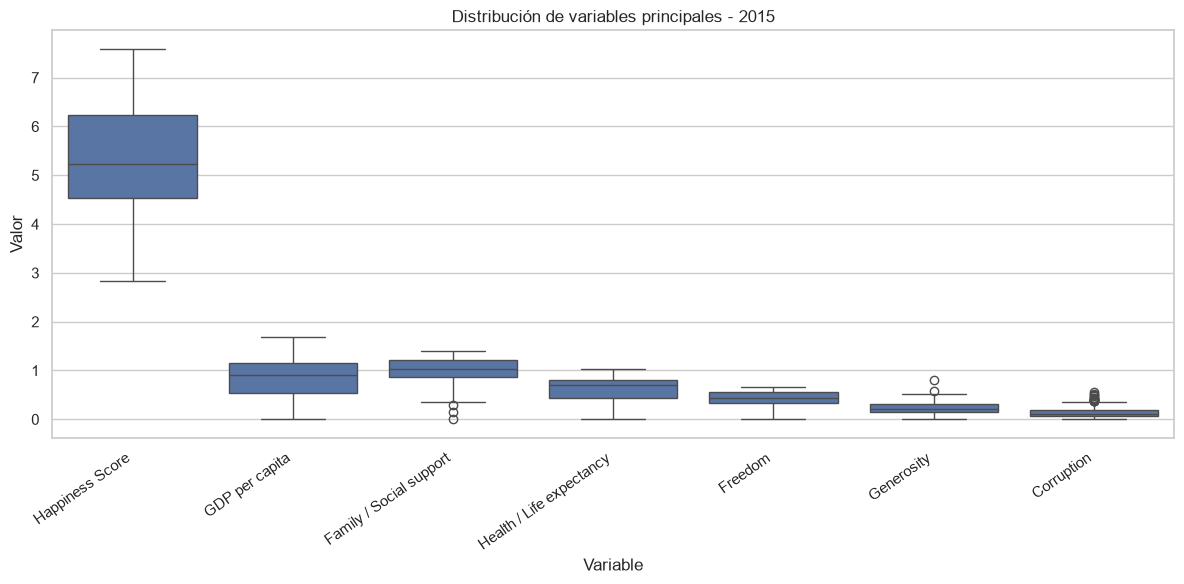

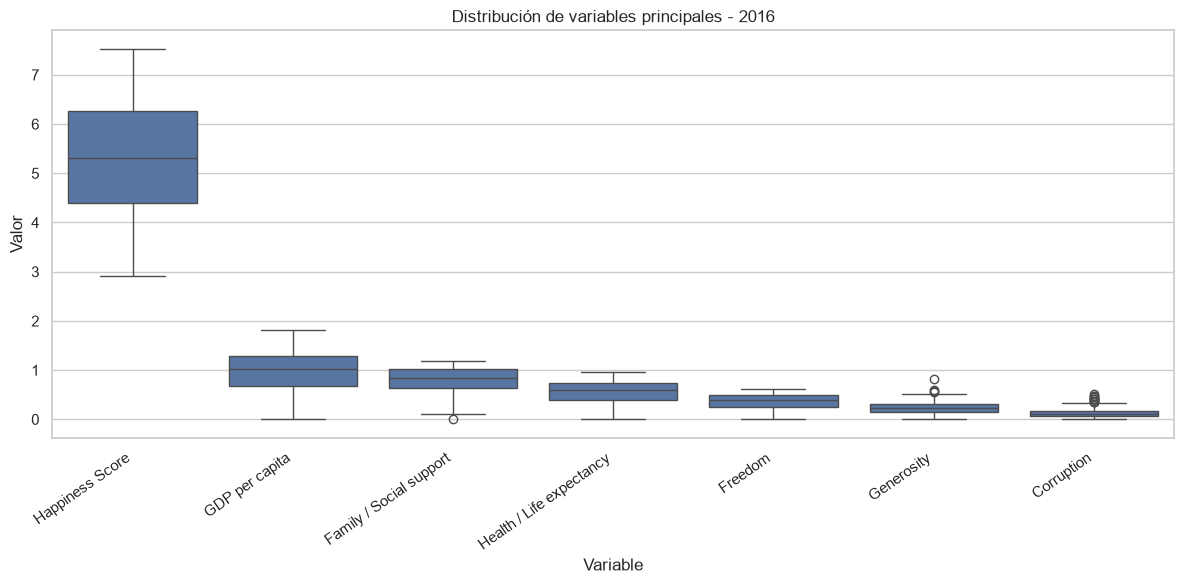

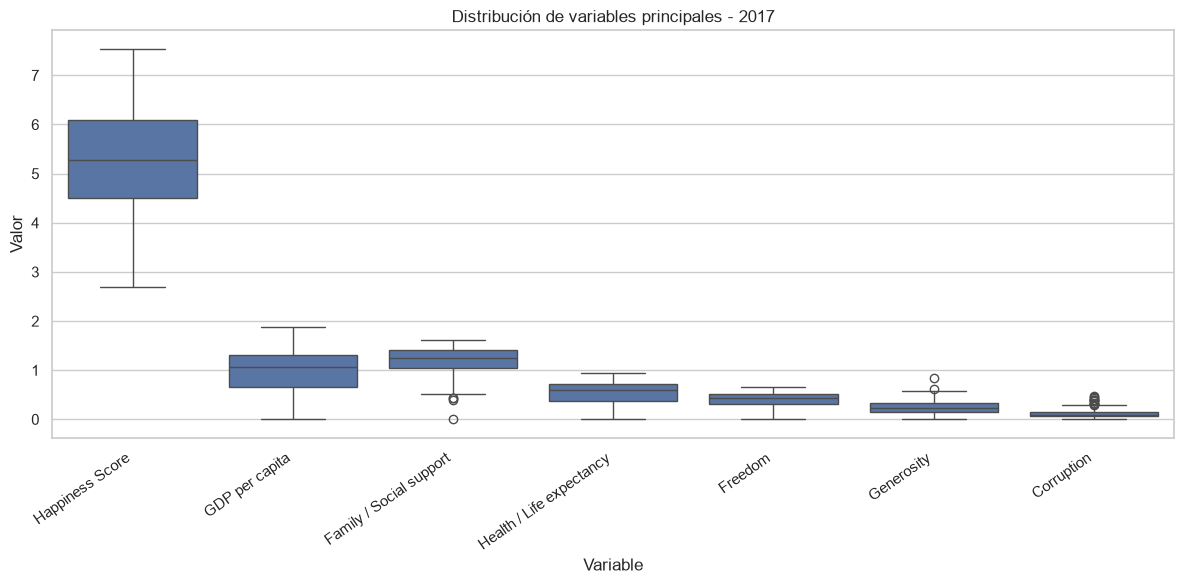

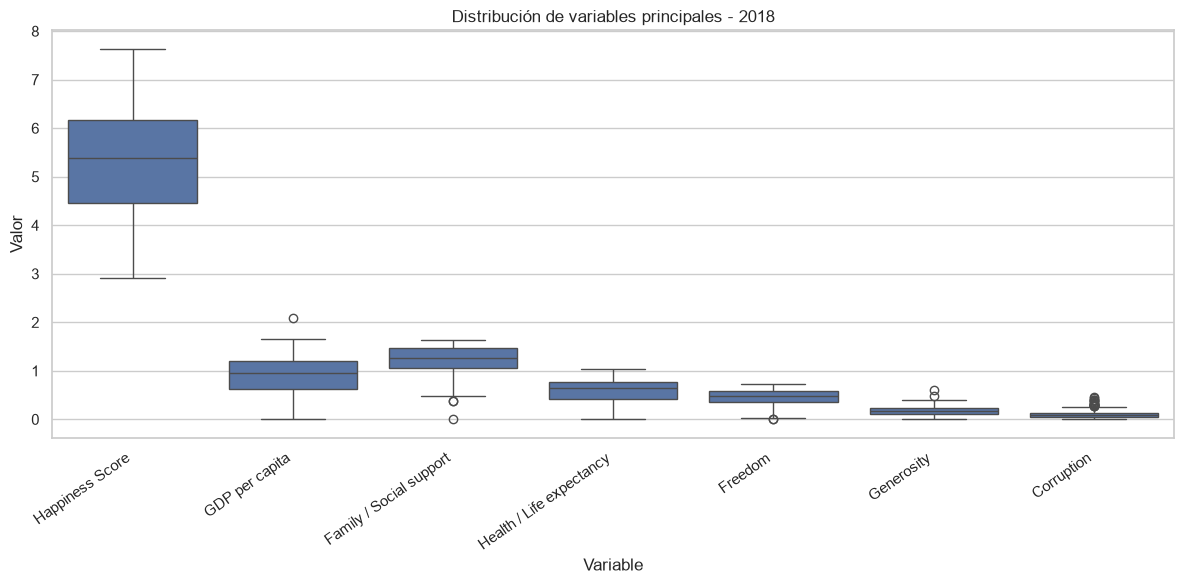

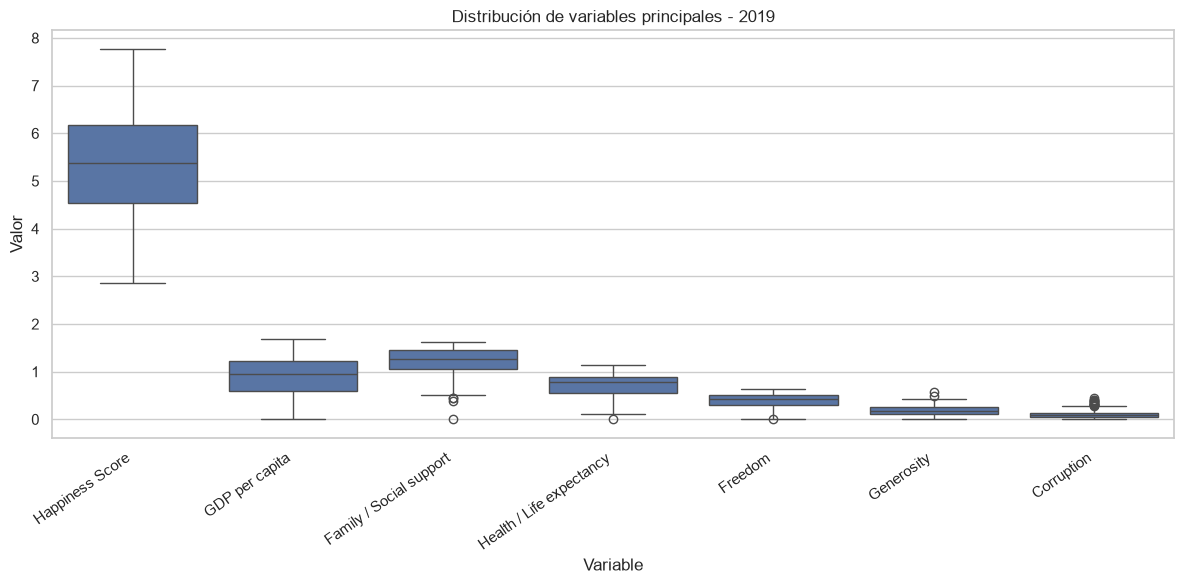

In [37]:
# ==========================================
# 7.4. VISUALIZACIÓN DE OUTLIERS
# ==========================================

import matplotlib.pyplot as plt
import seaborn as sns

# Correspondencia de las variables entre los años
variable_mapping = {
    "Happiness Score": [
        "Happiness Score",
        "Happiness.Score",
        "Score"
    ],
    "GDP per capita": [
        "Economy (GDP per Capita)",
        "Economy..GDP.per.Capita.",
        "GDP per capita"
    ],
    "Family / Social support": [
        "Family",
        "Social support"
    ],
    "Health / Life expectancy": [
        "Health (Life Expectancy)",
        "Health..Life.Expectancy.",
        "Healthy life expectancy"
    ],
    "Freedom": [
        "Freedom",
        "Freedom to make life choices"
    ],
    "Generosity": [
        "Generosity"
    ],
    "Corruption": [
        "Trust (Government Corruption)",
        "Trust..Government.Corruption.",
        "Perceptions of corruption"
    ]
}

for year, df in datasets.items():

    plot_data = []

    for variable, possible_columns in variable_mapping.items():

        column = next(
            (
                col for col in possible_columns
                if col in df.columns
            ),
            None
        )

        if column is not None:

            values = df[column].dropna()

            for value in values:
                plot_data.append({
                    "Variable": variable,
                    "Valor": value
                })

    plot_df = pd.DataFrame(plot_data)

    plt.figure(figsize=(12, 6))

    sns.boxplot(
        data=plot_df,
        x="Variable",
        y="Valor"
    )

    plt.title(f"Distribución de variables principales - {year}")
    plt.xlabel("Variable")
    plt.ylabel("Valor")
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.show()

In [38]:
# ==========================================
# 7.5. RESUMEN CONSOLIDADO DE OUTLIERS
# ==========================================

outlier_summary = (
    outliers_df[
        outliers_df["Cantidad de outliers"] > 0
    ][[
        "Año",
        "Variable",
        "Cantidad de outliers",
        "Porcentaje de outliers (%)"
    ]]
    .sort_values(
        by=["Año", "Cantidad de outliers"],
        ascending=[True, False]
    )
    .reset_index(drop=True)
)

if outlier_summary.empty:
    print("No se detectaron outliers mediante el método IQR.")
else:
    display(Markdown(
        outlier_summary.to_markdown(index=False)
    ))

|   Año | Variable                      |   Cantidad de outliers |   Porcentaje de outliers (%) |
|------:|:------------------------------|-----------------------:|-----------------------------:|
|  2015 | Trust (Government Corruption) |                     14 |                         8.86 |
|  2015 | Standard Error                |                     10 |                         6.33 |
|  2015 | Dystopia Residual             |                      5 |                         3.16 |
|  2015 | Family                        |                      3 |                         1.9  |
|  2015 | Generosity                    |                      2 |                         1.27 |
|  2016 | Trust (Government Corruption) |                     12 |                         7.64 |
|  2016 | Dystopia Residual             |                      6 |                         3.82 |
|  2016 | Generosity                    |                      4 |                         2.55 |
|  2016 | Family                        |                      1 |                         0.64 |
|  2017 | Trust..Government.Corruption. |                     13 |                         8.39 |
|  2017 | Dystopia.Residual             |                      6 |                         3.87 |
|  2017 | Family                        |                      4 |                         2.58 |
|  2017 | Generosity                    |                      2 |                         1.29 |
|  2018 | Perceptions of corruption     |                     17 |                        10.97 |
|  2018 | Social support                |                      3 |                         1.92 |
|  2018 | Freedom to make life choices  |                      2 |                         1.28 |
|  2018 | Generosity                    |                      2 |                         1.28 |
|  2018 | GDP per capita                |                      1 |                         0.64 |
|  2019 | Perceptions of corruption     |                     14 |                         8.97 |
|  2019 | Social support                |                      4 |                         2.56 |
|  2019 | Generosity                    |                      2 |                         1.28 |
|  2019 | Healthy life expectancy       |                      1 |                         0.64 |
|  2019 | Freedom to make life choices  |                      1 |                         0.64 |

In [39]:
# ==========================================
# 7.6. TOTAL DE OUTLIERS POR AÑO
# ==========================================

outlier_year_summary = (
    outliers_df
    .groupby("Año")
    .agg(
        Variables_analizadas=("Variable", "count"),
        Total_outliers=("Cantidad de outliers", "sum")
    )
    .reset_index()
)

display(Markdown(
    outlier_year_summary.to_markdown(index=False)
))

|   Año |   Variables_analizadas |   Total_outliers |
|------:|-----------------------:|-----------------:|
|  2015 |                     10 |               34 |
|  2016 |                     11 |               23 |
|  2017 |                     11 |               25 |
|  2018 |                      8 |               25 |
|  2019 |                      8 |               22 |

In [40]:
# ==========================================
# 7.7. VALIDACIÓN DE VALORES NEGATIVOS
# ==========================================

core_candidates = {
    "Happiness Score": [
        "Happiness Score", "Happiness.Score", "Score"
    ],
    "GDP": [
        "Economy (GDP per Capita)",
        "Economy..GDP.per.Capita.",
        "GDP per capita"
    ],
    "Family / Social support": [
        "Family", "Social support"
    ],
    "Health": [
        "Health (Life Expectancy)",
        "Health..Life.Expectancy.",
        "Healthy life expectancy"
    ],
    "Freedom": [
        "Freedom", "Freedom to make life choices"
    ],
    "Generosity": [
        "Generosity"
    ],
    "Corruption": [
        "Trust (Government Corruption)",
        "Trust..Government.Corruption.",
        "Perceptions of corruption"
    ]
}

negative_results = []

for year, df in datasets.items():

    for variable, candidates in core_candidates.items():

        column = next(
            (col for col in candidates if col in df.columns),
            None
        )

        if column is None:
            continue

        negative_rows = df[df[column] < 0]

        for _, row in negative_rows.iterrows():

            country_col = next(
                col for col in ["Country", "Country or region"]
                if col in df.columns
            )

            negative_results.append({
                "Año": year,
                "País": row[country_col],
                "Variable": variable,
                "Valor": row[column]
            })

negative_df = pd.DataFrame(negative_results)

if negative_df.empty:
    print("No se encontraron valores negativos en las variables principales.")
else:
    display(Markdown(
        negative_df.to_markdown(index=False)
    ))

No se encontraron valores negativos en las variables principales.


### Tratamiento de valores atípicos (Outliers)

Se aplicó el método del rango intercuartílico (IQR) a las variables numéricas de los cinco conjuntos de datos, utilizando como criterio de detección los límites Q1 − 1.5 × IQR y Q3 + 1.5 × IQR.

El análisis identificó 129 observaciones atípicas distribuidas entre los años 2015 y 2019. Las variables con mayor frecuencia de valores extremos fueron las relacionadas con las percepciones de corrupción, la generosidad y el apoyo social.

También se identificaron valores atípicos en variables específicas de determinados años, como Standard Error y Dystopia Residual.

Después de examinar los países y los valores involucrados, se determinó que la detección estadística no constituye evidencia suficiente para considerar estas observaciones como errores. Los valores extremos pueden reflejar diferencias socioeconómicas reales entre países.

Por esta razón, se decidió conservar los registros originales y no aplicar eliminación ni sustitución automática de valores atípicos. Las variables específicas de determinados años se documentarán durante la armonización del esquema y no se incorporarán al conjunto común de predictores.

Esta decisión permite preservar la información histórica y evitar la pérdida de datos válidos durante el proceso de limpieza.

In [41]:
# ==========================================
# 4.2.1. ARMONIZACIÓN DE ESQUEMAS
# ==========================================

%pip install -q tabulate

import pandas as pd
from IPython.display import display, Markdown

# Definir las equivalencias de columnas por año

column_mapping = {

    2015: {
        "Country": "country",
        "Happiness Rank": "happiness_rank",
        "Happiness Score": "happiness_score",
        "Economy (GDP per Capita)": "gdp",
        "Family": "social_support",
        "Health (Life Expectancy)": "health",
        "Freedom": "freedom",
        "Generosity": "generosity",
        "Trust (Government Corruption)": "corruption",
        "Region": "region"
    },

    2016: {
        "Country": "country",
        "Happiness Rank": "happiness_rank",
        "Happiness Score": "happiness_score",
        "Economy (GDP per Capita)": "gdp",
        "Family": "social_support",
        "Health (Life Expectancy)": "health",
        "Freedom": "freedom",
        "Generosity": "generosity",
        "Trust (Government Corruption)": "corruption",
        "Region": "region"
    },

    2017: {
        "Country": "country",
        "Happiness.Rank": "happiness_rank",
        "Happiness.Score": "happiness_score",
        "Economy..GDP.per.Capita.": "gdp",
        "Family": "social_support",
        "Health..Life.Expectancy.": "health",
        "Freedom": "freedom",
        "Generosity": "generosity",
        "Trust..Government.Corruption.": "corruption"
    },

    2018: {
        "Country or region": "country",
        "Overall rank": "happiness_rank",
        "Score": "happiness_score",
        "GDP per capita": "gdp",
        "Social support": "social_support",
        "Healthy life expectancy": "health",
        "Freedom to make life choices": "freedom",
        "Generosity": "generosity",
        "Perceptions of corruption": "corruption"
    },

    2019: {
        "Country or region": "country",
        "Overall rank": "happiness_rank",
        "Score": "happiness_score",
        "GDP per capita": "gdp",
        "Social support": "social_support",
        "Healthy life expectancy": "health",
        "Freedom to make life choices": "freedom",
        "Generosity": "generosity",
        "Perceptions of corruption": "corruption"
    }
}

# Definir el orden del esquema común

standard_columns = [
    "country",
    "year",
    "happiness_rank",
    "happiness_score",
    "gdp",
    "social_support",
    "health",
    "freedom",
    "generosity",
    "corruption",
    "region"
]

# Crear nuevos DataFrames sin modificar los originales

harmonized_datasets = {}

for year, df in datasets.items():

    mapping = column_mapping[year]

    # Verificar que existan las columnas originales
    missing_columns = [
        col for col in mapping
        if col not in df.columns
    ]

    if missing_columns:
        raise ValueError(
            f"Faltan columnas en {year}: {missing_columns}"
        )

    # Renombrar columnas
    harmonized_df = df.rename(
        columns=mapping
    ).copy()

    # Incorporar el año
    harmonized_df["year"] = year

    # Incorporar columnas ausentes como nulas
    for col in standard_columns:

        if col not in harmonized_df.columns:
            harmonized_df[col] = pd.NA

    # Organizar columnas
    harmonized_df = harmonized_df[
        standard_columns
    ]

    harmonized_datasets[year] = harmonized_df


# Unificar los cinco DataFrames
unified_df = pd.concat(
    harmonized_datasets.values(),
    ignore_index=True
)


# ==========================================
# VALIDACIÓN DEL ESQUEMA UNIFICADO
# ==========================================

validation_results = []

for year, df in harmonized_datasets.items():

    validation_results.append({
        "Año": year,
        "Filas": len(df),
        "Columnas": len(df.columns),
        "Columnas esperadas": (
            list(df.columns) == standard_columns
        ),
        "Valores nulos": int(df.isna().sum().sum())
    })

validation_df = pd.DataFrame(
    validation_results
)

print("RESUMEN DE DATASETS ARMONIZADOS")

print(
    validation_df.to_markdown(index=False)
)

print("\nDATASET UNIFICADO")

print(f"Filas totales: {len(unified_df)}")
print(f"Columnas totales: {len(unified_df.columns)}")

print("\nESTRUCTURA FINAL")

print(
    unified_df.head().to_markdown(index=False)
)

Note: you may need to restart the kernel to use updated packages.
RESUMEN DE DATASETS ARMONIZADOS
|   Año |   Filas |   Columnas | Columnas esperadas   |   Valores nulos |
|------:|--------:|-----------:|:---------------------|----------------:|
|  2015 |     158 |         11 | True                 |               0 |
|  2016 |     157 |         11 | True                 |               0 |
|  2017 |     155 |         11 | True                 |             155 |
|  2018 |     156 |         11 | True                 |             157 |
|  2019 |     156 |         11 | True                 |             156 |

DATASET UNIFICADO
Filas totales: 782
Columnas totales: 11

ESTRUCTURA FINAL
| country     |   year |   happiness_rank |   happiness_score |     gdp |   social_support |   health |   freedom |   generosity |   corruption | region         |
|:------------|-------:|-----------------:|------------------:|--------:|-----------------:|---------:|----------:|-------------:|-------------:


[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [43]:
from IPython.display import display, Markdown

# ==========================================
# 4.2.2 Data Type and Structural Validation
# ==========================================

# Check data types
print("TIPOS DE DATOS")
display(
    Markdown(
        pd.DataFrame({
            "Column": unified_df.columns,
            "Data type": unified_df.dtypes.astype(str).values,
            "Null values": unified_df.isnull().sum().values
        }).to_markdown(index=False)
    )
)

# Check missing values by column
print("\nVALORES NULOS POR COLUMNA")
null_summary = unified_df.isnull().sum().reset_index()
null_summary.columns = ["Variable", "Null values"]
null_summary = null_summary[null_summary["Null values"] > 0]

if not null_summary.empty:
    display(Markdown(null_summary.to_markdown(index=False)))
else:
    print("No se encontraron valores nulos.")

# Check duplicated country-year combinations
duplicate_country_year = unified_df.duplicated(
    subset=["country", "year"]
).sum()

# Check numeric columns
numeric_columns = unified_df.select_dtypes(
    include="number"
).columns.tolist()

print("\nVALIDACIONES GENERALES")
print(f"Registros totales: {len(unified_df)}")
print(f"Combinaciones país-año duplicadas: {duplicate_country_year}")
print(f"Columnas numéricas: {numeric_columns}")
print(f"Países únicos: {unified_df['country'].nunique()}")
print(f"Años incluidos: {sorted(unified_df['year'].unique())}")

TIPOS DE DATOS


| Column          | Data type   |   Null values |
|:----------------|:------------|--------------:|
| country         | str         |             0 |
| year            | int64       |             0 |
| happiness_rank  | int64       |             0 |
| happiness_score | float64     |             0 |
| gdp             | float64     |             0 |
| social_support  | float64     |             0 |
| health          | float64     |             0 |
| freedom         | float64     |             0 |
| generosity      | float64     |             0 |
| corruption      | float64     |             1 |
| region          | object      |           467 |


VALORES NULOS POR COLUMNA


| Variable   |   Null values |
|:-----------|--------------:|
| corruption |             1 |
| region     |           467 |


VALIDACIONES GENERALES
Registros totales: 782
Combinaciones país-año duplicadas: 0
Columnas numéricas: ['year', 'happiness_rank', 'happiness_score', 'gdp', 'social_support', 'health', 'freedom', 'generosity', 'corruption']
Países únicos: 170
Años incluidos: [np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019)]


In [44]:
# 4.3 Treatment of Null, Duplicate, and Outlier Values

# Create a working copy without modifying the harmonized dataset
analysis_df = unified_df.copy()

# Document data treatment decisions
treatment_decisions = pd.DataFrame([
    {
        "Issue": "Missing values in corruption",
        "Decision": "Preserve",
        "Reason": "One original missing value in the 2018 dataset."
    },
    {
        "Issue": "Missing values in region",
        "Decision": "Preserve",
        "Reason": "Region is unavailable in the 2017-2019 source datasets."
    },
    {
        "Issue": "Duplicate records",
        "Decision": "No removal",
        "Reason": "No duplicated country-year combinations were detected."
    },
    {
        "Issue": "Outliers",
        "Decision": "Preserve",
        "Reason": "Potentially valid observations requiring contextual interpretation."
    },
    {
        "Issue": "Happiness rank",
        "Decision": "Exclude from model predictors",
        "Reason": "Avoid potential target leakage."
    }
])

print("DATASET DE TRABAJO")
print(f"Original unified dataset: {unified_df.shape}")
print(f"Working dataset: {analysis_df.shape}")
print(f"Original dataset modified: {not unified_df.equals(analysis_df)}")

print("\nDECISIONES DE TRATAMIENTO")
print(treatment_decisions.to_markdown(index=False))

DATASET DE TRABAJO
Original unified dataset: (782, 11)
Working dataset: (782, 11)
Original dataset modified: False

DECISIONES DE TRATAMIENTO
| Issue                        | Decision                      | Reason                                                              |
|:-----------------------------|:------------------------------|:--------------------------------------------------------------------|
| Missing values in corruption | Preserve                      | One original missing value in the 2018 dataset.                     |
| Missing values in region     | Preserve                      | Region is unavailable in the 2017-2019 source datasets.             |
| Duplicate records            | No removal                    | No duplicated country-year combinations were detected.              |
| Outliers                     | Preserve                      | Potentially valid observations requiring contextual interpretation. |
| Happiness rank               | Exclude from mo

In [45]:
# 4.3.1 Variable Role Definition

# Define the target variable
target_variable = "happiness_score"

# Define numerical predictors
predictor_variables = [
    "gdp",
    "social_support",
    "health",
    "freedom",
    "generosity",
    "corruption"
]

# Define identifiers and descriptive variables
identifier_variables = ["country", "year"]
descriptive_variables = ["happiness_rank", "region"]

# Create variable classification
variable_roles = pd.DataFrame([
    {"Variable": col, "Role": "Target"} 
    for col in [target_variable]
] + [
    {"Variable": col, "Role": "Predictor"} 
    for col in predictor_variables
] + [
    {"Variable": col, "Role": "Identifier"} 
    for col in identifier_variables
] + [
    {"Variable": col, "Role": "Descriptive"}
    for col in descriptive_variables
])

# Validate the classification
classified_variables = (
    [target_variable]
    + predictor_variables
    + identifier_variables
    + descriptive_variables
)

print("CLASIFICACIÓN DE VARIABLES")
print(variable_roles.to_markdown(index=False))

print("\nVALIDACIÓN")
print(f"Total de columnas clasificadas: {len(classified_variables)}")
print(f"Total de columnas del dataset: {len(analysis_df.columns)}")
print(f"Todas las columnas están clasificadas: "
      f"{set(classified_variables) == set(analysis_df.columns)}")
print(f"Valores nulos en el target: "
      f"{analysis_df[target_variable].isnull().sum()}")
print(f"Valores nulos en los predictores:\n"
      f"{analysis_df[predictor_variables].isnull().sum().to_string()}")

CLASIFICACIÓN DE VARIABLES
| Variable        | Role        |
|:----------------|:------------|
| happiness_score | Target      |
| gdp             | Predictor   |
| social_support  | Predictor   |
| health          | Predictor   |
| freedom         | Predictor   |
| generosity      | Predictor   |
| corruption      | Predictor   |
| country         | Identifier  |
| year            | Identifier  |
| happiness_rank  | Descriptive |
| region          | Descriptive |

VALIDACIÓN
Total de columnas clasificadas: 11
Total de columnas del dataset: 11
Todas las columnas están clasificadas: True
Valores nulos en el target: 0
Valores nulos en los predictores:
gdp               0
social_support    0
health            0
freedom           0
generosity        0
corruption        1


In [46]:
# 4.3.2 Contextual Analysis of Missing Values

# Identify the row with the missing corruption value
missing_corruption = analysis_df[
    analysis_df["corruption"].isna()
]

print("REGISTRO CON VALOR AUSENTE")
print(
    missing_corruption[
        ["country", "year", "happiness_score", "gdp",
         "social_support", "health", "freedom", "generosity",
         "corruption"]
    ].to_markdown(index=False)
)

# Analyze corruption distribution for 2018
corruption_2018 = analysis_df.loc[
    analysis_df["year"] == 2018, "corruption"
]

print("\nDISTRIBUCIÓN DE CORRUPTION EN 2018")
print(
    corruption_2018.describe().to_frame("Value").to_markdown()
)

print("\nVALIDACIÓN")
print(f"Registros con corruption ausente: {len(missing_corruption)}")
print(f"Registros de 2018: {len(corruption_2018)}")
print(f"Valores disponibles en 2018: {corruption_2018.notna().sum()}")

REGISTRO CON VALOR AUSENTE
| country              |   year |   happiness_score |   gdp |   social_support |   health |   freedom |   generosity |   corruption |
|:---------------------|-------:|------------------:|------:|-----------------:|---------:|----------:|-------------:|-------------:|
| United Arab Emirates |   2018 |             6.774 | 2.096 |            0.776 |     0.67 |     0.284 |        0.186 |          nan |

DISTRIBUCIÓN DE CORRUPTION EN 2018
|       |       Value |
|:------|------------:|
| count | 155         |
| mean  |   0.112     |
| std   |   0.0964918 |
| min   |   0         |
| 25%   |   0.051     |
| 50%   |   0.082     |
| 75%   |   0.137     |
| max   |   0.457     |

VALIDACIÓN
Registros con corruption ausente: 1
Registros de 2018: 156
Valores disponibles en 2018: 155


In [47]:
# 4.3.3 Final Data Treatment Documentation

# Update the missing-value decision
treatment_decisions.loc[
    treatment_decisions["Issue"] == "Missing values in corruption",
    "Reason"
] = (
    "The missing value for United Arab Emirates (2018) "
    "is preserved. Imputation will be evaluated during model preparation."
)

# Final integrity checks
integrity_summary = pd.DataFrame([
    {
        "Validation": "Original records",
        "Result": len(unified_df),
        "Expected": 782
    },
    {
        "Validation": "Working records",
        "Result": len(analysis_df),
        "Expected": 782
    },
    {
        "Validation": "Missing target values",
        "Result": analysis_df["happiness_score"].isna().sum(),
        "Expected": 0
    },
    {
        "Validation": "Duplicated country-year records",
        "Result": analysis_df.duplicated(
            subset=["country", "year"]
        ).sum(),
        "Expected": 0
    },
    {
        "Validation": "Missing corruption values",
        "Result": analysis_df["corruption"].isna().sum(),
        "Expected": 1
    }
])

print("FINAL DATA INTEGRITY CHECK")
print(integrity_summary.to_markdown(index=False))

print("\nDOCUMENTED TREATMENT DECISIONS")
print(treatment_decisions.to_markdown(index=False))

print("\nOriginal dataset preserved:", unified_df.shape == (782, 11))
print("Working dataset preserved:", analysis_df.shape == (782, 11))

FINAL DATA INTEGRITY CHECK
| Validation                      |   Result |   Expected |
|:--------------------------------|---------:|-----------:|
| Original records                |      782 |        782 |
| Working records                 |      782 |        782 |
| Missing target values           |        0 |          0 |
| Duplicated country-year records |        0 |          0 |
| Missing corruption values       |        1 |          1 |

DOCUMENTED TREATMENT DECISIONS
| Issue                        | Decision                      | Reason                                                                                                                 |
|:-----------------------------|:------------------------------|:-----------------------------------------------------------------------------------------------------------------------|
| Missing values in corruption | Preserve                      | The missing value for United Arab Emirates (2018) is preserved. Imputation will be e

In [48]:

# 4.4 Final Dataset Export and Validation

from pathlib import Path

# Locate project root
candidates = [
    Path.cwd(),
    *Path.cwd().parents
]

project_root = next(
    (path for path in candidates if (path / "data" / "raw").is_dir()),
    None
)

if project_root is None:
    raise FileNotFoundError(
        "Could not locate the project root containing data/raw."
    )

# Create processed dataset without modifying previous DataFrames
processed_df = analysis_df.copy()

# Explicitly handle structurally unavailable regions
processed_df["region"] = (
    processed_df["region"]
    .fillna("Not available in source")
)

# Preserve original missing corruption value for later
# imputation inside the machine learning pipeline

# Export dataset
output_dir = project_root / "data" / "processed"
output_dir.mkdir(parents=True, exist_ok=True)

output_file = output_dir / "happiness_unified.csv"

processed_df.to_csv(output_file, index=False)

# Final validation
print("FINAL DATASET VALIDATION")
print(f"Output file: {output_file}")
print(f"Rows: {len(processed_df)}")
print(f"Columns: {len(processed_df.columns)}")
print(f"Duplicated country-year records: {processed_df.duplicated(subset=['country', 'year']).sum()}")
print(f"Missing target values: {processed_df['happiness_score'].isna().sum()}")
print(f"Missing corruption values: {processed_df['corruption'].isna().sum()}")
print(f"Missing region values: {processed_df['region'].isna().sum()}")
print(f"Structural region labels: {(processed_df['region'] == 'Not available in source').sum()}")
print(f"Original dataset preserved: {unified_df.shape == (782, 11)}")
print(f"Working dataset preserved: {analysis_df.shape == (782, 11)}")
print(f"Export successful: {output_file.exists()}")


FINAL DATASET VALIDATION
Output file: c:\Users\USER\Desktop\ETL-Workshop-3\data\processed\happiness_unified.csv
Rows: 782
Columns: 11
Duplicated country-year records: 0
Missing target values: 0
Missing corruption values: 1
Missing region values: 0
Structural region labels: 467
Original dataset preserved: True
Working dataset preserved: True
Export successful: True


### 4. Data Cleaning Decisions — Final Results

The five World Happiness Report datasets (2015–2019) were explored, harmonized, and integrated into a unified analytical dataset containing 782 observations and 11 standardized columns.

The cleaning process identified one missing value in the `corruption` variable for United Arab Emirates (2018), while the `region` variable was unavailable in the original datasets from 2017 to 2019. These structural missing values were explicitly labeled as "Not available in source" in the processed dataset.

No duplicated country-year combinations were detected. Potential outliers identified through the IQR method were preserved because they may represent valid observations rather than data-entry errors.

The `happiness_rank` variable was retained for descriptive analysis but excluded from the model predictors to avoid potential target leakage. The missing value in `corruption` was preserved for subsequent imputation within the machine learning preprocessing pipeline.

The final dataset was exported to `data/processed/happiness_unified.csv`, preserving the original source files and maintaining all 782 observations.

**Outcome:** A unified, documented, and validated dataset ready for feature engineering and regression modeling.